# 데이터분석 미니프로젝트 — 학습 노트북 (train.ipynb)

**과제**: Target_1(D+3 KOSPI 상승), Target_2(D+3 건강식품 지수 상승) 확률 예측 · 평가지표 AUC · Private 200일 평균 점수 60점
**최우선 목표: 과적합 방지** — Public(100일)이 아니라 Private(200일)에서 무너지지 않는 모델

## 설계 방향 (EDA 근거: `01_EDA_피처인사이트.ipynb`)
| 갈래 | 과적합 방지 장치 | 이 노트북 위치 |
| --- | --- | --- |
| ① 검증 설계 | 시계열 5-fold CV(expanding) + **gap=3** (D+3 Target이 검증 구간 가격과 겹치는 것 차단) · **평균±표준편차**로 판단 · Train-Valid 격차 감시 · Public은 참고만 | §2 |
| ② Feature Engineering | 과거 값만 사용 · Target별 피처셋 분리 · 요일 대리변수 대량 투입 금지 · **Selection은 fold 안에서만** · 결측 대체도 fold Train 기준(Pipeline) | §3 |
| ③ 모델 | 얕은 트리·큰 leaf·L2 정규화 · 이질 모델 소프트보팅으로 분산 감소 · 최종 선택 기준 = **평균 − 표준편차** | §4~5 |

## 목차
0. 실행 메모 (중복 실행 방지)  1. 설정·데이터  2. 검증 설계 + 실험 기록/누적 시각화  3. 피처 블록
4. 실험 E0~E5 (각 실험 후 누적 그래프)  5. 최종 선택  5-1. Baseline 비교 시각화  5-2. 전체 실험 최종 비교  6. 제출 파일  7. 개선 백로그

## 0. 실행 메모 — 중복 실행 방지 📝

- **실험 결과는 `experiments.csv`에 캐시**된다. 실험마다 `(실험명, Target, 설정 해시)`를 저장하고, 같은 설정이면 **학습을 건너뛰고 저장된 결과를 재사용**한다.
  → `Run All`을 다시 눌러도 이미 돌린 실험은 몇 초 안에 넘어간다.
- 피처 블록·모델 파라미터를 **바꾸면 해시가 달라져 그 실험만 자동 재실행**된다 (다른 실험은 그대로).
- 강제로 다시 돌리려면 §1의 `FORCE = True` (전체) 또는 `run(..., force=True)` (해당 실험만).
- 처음부터 다시 기록하려면 `experiments.csv`를 삭제한다.
- CV는 **Train만** 쓰므로 `MODE`(public/private)를 바꿔도 캐시는 그대로 유효하다. MODE 변경 후에는 §6 제출만 다시 실행하면 된다.
- 새 실험은 §4 맨 아래에 셀을 추가하고 `run('E6_이름', ...)` → `show_progress()` 순서로 쓴다. 그래프에 자동 누적된다.

## 1. 설정 · 데이터

In [1]:
import warnings, json, hashlib, time, os
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None
    print('xgboost 미설치 → XGB 실험은 건너뜀 (pip install xgboost)')

plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

# ⚠️ 제출 전 확인: MODE · 반/이름 · 회차  (입력 파일·파일명·주소가 함께 바뀜)
MODE = 'public'                 # 'public' 또는 'private'
CLASS, NAME, PUBLIC_ROUND = '4반', '최승우', 2   # 회차: 제출할 때마다 +1 (최대 4회)
OVERWRITE = False              # 같은 이름 제출 파일이 있으면 저장 중단 (기존 제출본 보호)
CFG = {
    'public':  dict(test='test_public.csv',  sample='sample_submission_public.csv',
                    out=f'public_{CLASS}_{NAME}_{PUBLIC_ROUND}.csv', form='https://forms.gle/S8X2XRqHtAGuvwgq5'),
    'private': dict(test='test_private.csv', sample='sample_submission_private.csv',
                    out=f'private_{CLASS}_{NAME}.csv',             form='https://forms.gle/eyvChbVYL6MhhdtaA'),
}[MODE]

SEED = 42
RESULTS_FILE = 'experiments.csv'
FORCE = False                   # True면 캐시 무시하고 모든 실험 재실행

train = pd.read_csv('train.csv', encoding='cp949')
test = pd.read_csv(CFG['test'], encoding='cp949')
TARGETS = ['Target_1', 'Target_2']
RAW = [c for c in train.columns if c not in TARGETS + ['Time_step', 'Weekday']]

# 피처는 시간순으로 이어 붙여 '과거 값'만으로 만든다 (Test의 Target은 쓰지 않음, Test 행도 자신의 과거만 참조)
full = pd.concat([train, test], ignore_index=True).sort_values('Time_step').reset_index(drop=True)
is_tr = full.Time_step.isin(train.Time_step).values
Y = full.loc[is_tr, TARGETS].astype(int).reset_index(drop=True)
print(MODE, '| train', train.shape, '| test', test.shape, '| 제출 파일명:', CFG['out'])

xgboost 미설치 → XGB 실험은 건너뜀 (pip install xgboost)
public | train (924, 287) | test (100, 287) | 제출 파일명: public_4반_최승우_2.csv


## 2. 검증 설계 · 실험 기록 · 누적 시각화

- `TimeSeriesSplit(n_splits=5, gap=3)`: 항상 **과거로 학습 → 미래로 검증**. fold 검증 구간 ≈ 154일로 Public(100일)과 비슷한 규모.
- 각 fold에서 Train AUC와 Valid AUC를 함께 기록 → **격차(Train−Valid)가 과적합 지표**.
- 결측 대체·스케일링·Selection은 모두 모델 Pipeline 안에 있어 **fold Train으로만 fit** 된다 (Train-Test Contamination 방지).

In [2]:
TSCV = TimeSeriesSplit(n_splits=5, gap=3)
REG = {}                                              # (실험명, target) → (블록, 모델): §5 최종 학습용

def model_sig(model):
    """캐시 키: 모델 구조 + 단순 파라미터 (함수 객체 메모리 주소 등은 제외해 세션 간 키 고정)"""
    p = model.get_params(deep=True)
    simple = {k: v for k, v in p.items() if isinstance(v, (int, float, str, bool, type(None)))}
    names = [type(v).__name__ for k, v in p.items() if hasattr(v, 'fit')]
    return json.dumps([type(model).__name__, sorted(names), sorted(simple.items(), key=str)], default=str)

def load_log():
    return pd.read_csv(RESULTS_FILE) if os.path.exists(RESULTS_FILE) else pd.DataFrame()

def cv_auc(model, Xd, y):
    tr_s, va_s = [], []
    for tr, va in TSCV.split(Xd):
        m = clone(model).fit(Xd.iloc[tr], y.iloc[tr])
        tr_s.append(roc_auc_score(y.iloc[tr], m.predict_proba(Xd.iloc[tr])[:, 1]))
        va_s.append(roc_auc_score(y.iloc[va], m.predict_proba(Xd.iloc[va])[:, 1]))
    return np.array(tr_s), np.array(va_s)

def run(name, target, blocks, model, note='', force=False):
    """실험 1건 실행 + 기록. 같은 설정이면 캐시 재사용(중복 실행 방지)."""
    REG[(name, target)] = (blocks, model)
    Xd = make_X(blocks)[is_tr].reset_index(drop=True)
    key = hashlib.md5((target + json.dumps(sorted(Xd.columns)) + model_sig(model)).encode()).hexdigest()[:10]
    log = load_log()
    hit = log.index[(log.get('name') == name) & (log.get('target') == target)] if len(log) else []
    if len(hit) and log.at[hit[0], 'key'] == key and not (FORCE or force):
        r = log.loc[hit[0]]
        print(f'⏭  {name} | {target}: 캐시 사용  Valid {r.valid_mean:.4f} ± {r.valid_std:.4f}')
        return
    t0 = time.time()
    tr_s, va_s = cv_auc(model, Xd, Y[target])
    row = dict(name=name, target=target, key=key, n_feat=Xd.shape[1], blocks='+'.join(blocks),
               train_mean=tr_s.mean(), valid_mean=va_s.mean(), valid_std=va_s.std(),
               folds=json.dumps(np.round(va_s, 4).tolist()), note=note, sec=round(time.time() - t0, 1))
    if len(hit):
        for k, v in row.items(): log.at[hit[0], k] = v          # 같은 실험명은 자리 유지하며 갱신
    else:
        log = pd.concat([log, pd.DataFrame([row])], ignore_index=True)
    log.to_csv(RESULTS_FILE, index=False)
    print(f'✅ {name} | {target}: Valid {va_s.mean():.4f} ± {va_s.std():.4f} | Train {tr_s.mean():.4f} | {row["sec"]}s')

def show_progress(baseline='E0_baseline'):
    """누적 성능 그래프: Baseline 대비 Valid AUC(평균±std)와 과적합 격차"""
    log = load_log()
    if log.empty: return
    fig, ax = plt.subplots(2, 3, figsize=(20, 8), gridspec_kw={'height_ratios': [2, 1]})
    for i, t in enumerate(TARGETS):
        d = log[log.target == t].reset_index(drop=True)
        base = d.loc[d.name == baseline, 'valid_mean']
        ax[0, i].errorbar(d.name, d.valid_mean, yerr=d.valid_std, fmt='o-', capsize=4, label='Valid AUC 평균±std')
        ax[0, i].plot(d.name, d.valid_mean - d.valid_std, 'v:', c='gray', label='선택 기준 (평균-std)')
        if len(base): ax[0, i].axhline(base.iloc[0], ls='--', c='r', label=f'Baseline {base.iloc[0]:.3f}')
        ax[0, i].set_title(f'{t} — CV Valid AUC'); ax[0, i].legend(fontsize=8)
        gap = d.train_mean - d.valid_mean
        ax[1, i].bar(d.name, gap, color=np.where(gap > .15, 'tomato', 'seagreen'))
        ax[1, i].set_title('Train-Valid 격차 (과적합 지표, 낮을수록 좋음 · 빨강 > 0.15)')
    piv = log.pivot_table(index='name', columns='target', values='valid_mean', sort=False)
    piv['평균'] = piv[TARGETS].mean(axis=1, skipna=False)   # 한 Target만 돌린 실험은 평균 비움 (Δ 왜곡 방지)
    ax[0, 2].plot(piv.index, piv['평균'], 'o-', c='purple')
    if baseline in piv.index: ax[0, 2].axhline(piv.loc[baseline, '평균'], ls='--', c='r')
    ax[0, 2].set_title('최종 점수 기준: 두 Target 평균 AUC')
    ax[1, 2].axis('off')
    for a in ax.flat: a.tick_params(axis='x', rotation=30, labelsize=8)
    plt.tight_layout(); plt.show()
    if baseline in piv.index:
        piv['Δ vs Baseline'] = piv['평균'] - piv.loc[baseline, '평균']
    display(piv.round(4))

## 3. 피처 블록 (모두 과거 값만 사용)

| 블록 | 내용 | 근거 (EDA §) |
| --- | --- | --- |
| `raw`, `chg1`, `wd_num` | Baseline 재현용: 원값 + 전일 대비 변화율 + 요일 숫자 | Baseline |
| `wd_onehot` | 요일 one-hot (※ D+3 요일 one-hot은 같은 열의 순서만 바뀐 것이라 중복 → 제외) | §1 |
| `d3ratio` | **지난 4주 'D+3 요일' 평균 / 오늘** (쇼핑L1 11개 + 식품·생활건강 평균) | §8: 단일 AUC 0.957 |
| `z20_kw` | 키워드 20일 z-score (평균회귀, 애매한 요일 2·5 보강) | §4 |
| `fi_chg` | 금융 1·3·5일 변화율 + 20일 변동성 | §5: 미국지수 chg1 |
| `samewd_grp` | 쇼핑L1·L2·키워드 군별 '같은 요일 4주 평균 대비' 중앙값 (공통 요인 3개로 압축) | §6 |

전처리: 상수 컬럼 제거(Train 기준) · 쇼핑/키워드 0 → NaN · inf → NaN · 결측 대체는 Pipeline에서 fold Train 중앙값.

In [3]:
const_cols = [c for c in RAW if train[c].nunique() <= 1]
X0 = full[[c for c in RAW if c not in const_cols]].copy()
click_cols = [c for c in X0 if c.startswith(('SH', 'KE'))]
X0[click_cols] = X0[click_cols].mask(X0[click_cols] == 0)          # 클릭량 0 → NaN (날씨 강수량 0은 유지)
cols = lambda p: [c for c in X0 if c.startswith(p)]

def same_wd_ratio(D):            # 지난 4주 같은 요일 평균 대비
    return D / (sum(D.shift(7 * k) for k in range(1, 5)) / 4)

def d3_ratio(D):                 # 지난 4주 'D+3 요일'(= 4,11,18,25일 전) 평균 / 오늘
    return (sum(D.shift(4 + 7 * k) for k in range(4)) / 4) / D

def z20(D):
    return (D - D.rolling(20).mean()) / D.rolling(20).std()

sh1 = X0[cols('SH1')]
fi = X0[cols('FI')]
BLOCKS = {
    'raw':        X0,
    'chg1':       X0.pct_change(1, fill_method=None).add_suffix('_chg1'),
    'wd_num':     full[['Weekday']],
    'wd_onehot':  pd.get_dummies(full.Weekday, prefix='wd').astype(int),
    'd3ratio':    pd.concat([d3_ratio(sh1).add_suffix('_d3r'),
                             d3_ratio(sh1[['SH1_쇼핑1_식품', 'SH1_쇼핑1_생활건강']].mean(axis=1)).rename('식품건강_d3r')], axis=1),
    'z20_kw':     z20(X0[cols('KE')]).add_suffix('_z20'),
    'fi_chg':     pd.concat([fi.pct_change(k, fill_method=None).add_suffix(f'_chg{k}') for k in (1, 3, 5)]
                            + [fi.pct_change(1, fill_method=None).rolling(20).std().add_suffix('_vol20')], axis=1),
    'samewd_grp': pd.DataFrame({f'{p}_sameWD_med': same_wd_ratio(X0[cols(p)]).median(axis=1) for p in ('SH1', 'SH2', 'KE')}),
}

def make_X(blocks):
    X = pd.concat([BLOCKS[b] for b in blocks], axis=1).replace([np.inf, -np.inf], np.nan)
    return X.loc[:, ~X.columns.duplicated()]      # 블록 간 같은 열(예: fi_chg와 chg1의 FI_*_chg1) 중복 제거

pd.Series({b: BLOCKS[b].shape[1] for b in BLOCKS}, name='피처 수')

raw           282
chg1          282
wd_num          1
wd_onehot       7
d3ratio        12
z20_kw         50
fi_chg         72
samewd_grp      3
Name: 피처 수, dtype: int64

## 4. 실험 — 모델 팩토리

모든 모델은 `결측 대체 → (스케일) → (fold 내 Selection) → 분류기` Pipeline. 정규화 강도가 과적합 방지의 핵심 손잡이다.

In [4]:
def pipe(clf, k=None, scale=False):
    steps = [SimpleImputer(strategy='median')]
    if scale: steps.append(StandardScaler())
    if k: steps.append(SelectKBest(f_classif, k=k))          # fold Train으로만 선택 (Leakage 방지)
    return make_pipeline(*steps, clf)

def rf_base():   # 원본 Baseline 파라미터
    return RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_split=10, min_samples_leaf=5, random_state=SEED, n_jobs=-1)

def rf_reg():    # 정규화 강화: 얕게, leaf 크게, 피처 샘플링
    return RandomForestClassifier(n_estimators=300, max_depth=4, min_samples_leaf=20, max_features='sqrt', random_state=SEED, n_jobs=-1)

def lr_reg(C=0.1):
    return LogisticRegression(C=C, max_iter=3000)

def xgb_reg():
    return XGBClassifier(n_estimators=300, max_depth=2, learning_rate=0.03, subsample=0.8, colsample_bytree=0.5,
                         min_child_weight=10, reg_lambda=5, eval_metric='logloss', random_state=SEED, n_jobs=-1)

FEATS = {   # Target별 피처셋 (EDA 근거)
    'Target_1': ['fi_chg', 'samewd_grp', 'wd_onehot'],
    'Target_2': ['wd_onehot', 'd3ratio', 'z20_kw'],
}

### E0. Baseline 재현 (기준선)
원본 Baseline과 같은 피처(원값+전일 변화율+요일)·같은 RF 파라미터. 단, 평가는 단일 7:3 분할이 아니라 **CV**라서 원본 노트북 출력값과 수치는 다를 수 있다. 이후 모든 실험은 이 빨간 점선과 비교한다.

⏭  E0_baseline | Target_1: 캐시 사용  Valid 0.5221 ± 0.0181
⏭  E0_baseline | Target_2: 캐시 사용  Valid 0.9451 ± 0.0093


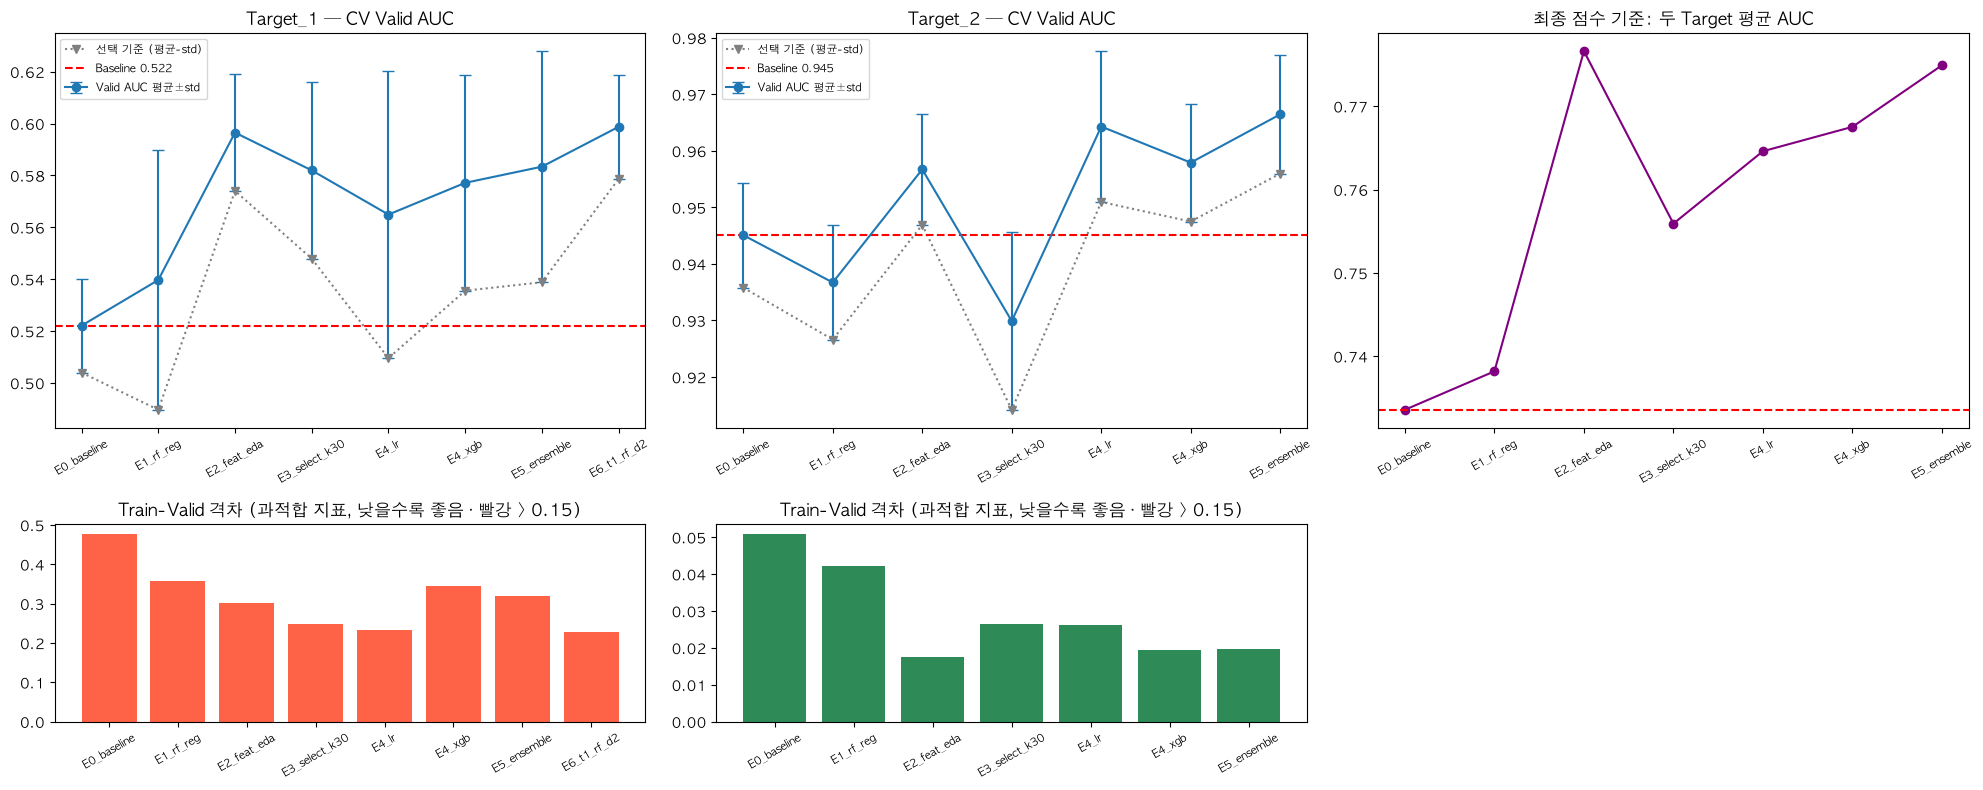

target,Target_1,Target_2,평균,Δ vs Baseline
name,,,,
E0_baseline,0.5221,0.9451,0.7336,0.0000
E1_rf_reg,0.5397,0.9367,0.7382,0.0046
E2_feat_eda,0.5965,0.9567,0.7766,0.0430
E3_select_k30,0.5819,0.9299,0.7559,0.0223
E4_lr,0.5649,0.9643,0.7646,0.0310
E4_xgb,0.5771,0.9579,0.7675,0.0339
E5_ensemble,0.5834,0.9665,0.7749,0.0413
E6_t1_rf_d2,0.5987,NaN,NaN,NaN


In [5]:
for t in TARGETS:
    run('E0_baseline', t, ['raw', 'chg1', 'wd_num'], pipe(rf_base()), note='원본 Baseline 재현')
show_progress()

### E1. 같은 피처 + 정규화 강화
가설: 피처는 그대로 두고 트리를 얕게/leaf를 크게 하면 **격차(과적합)는 줄고 Valid는 유지 또는 상승**.

⏭  E1_rf_reg | Target_1: 캐시 사용  Valid 0.5397 ± 0.0500
⏭  E1_rf_reg | Target_2: 캐시 사용  Valid 0.9367 ± 0.0101


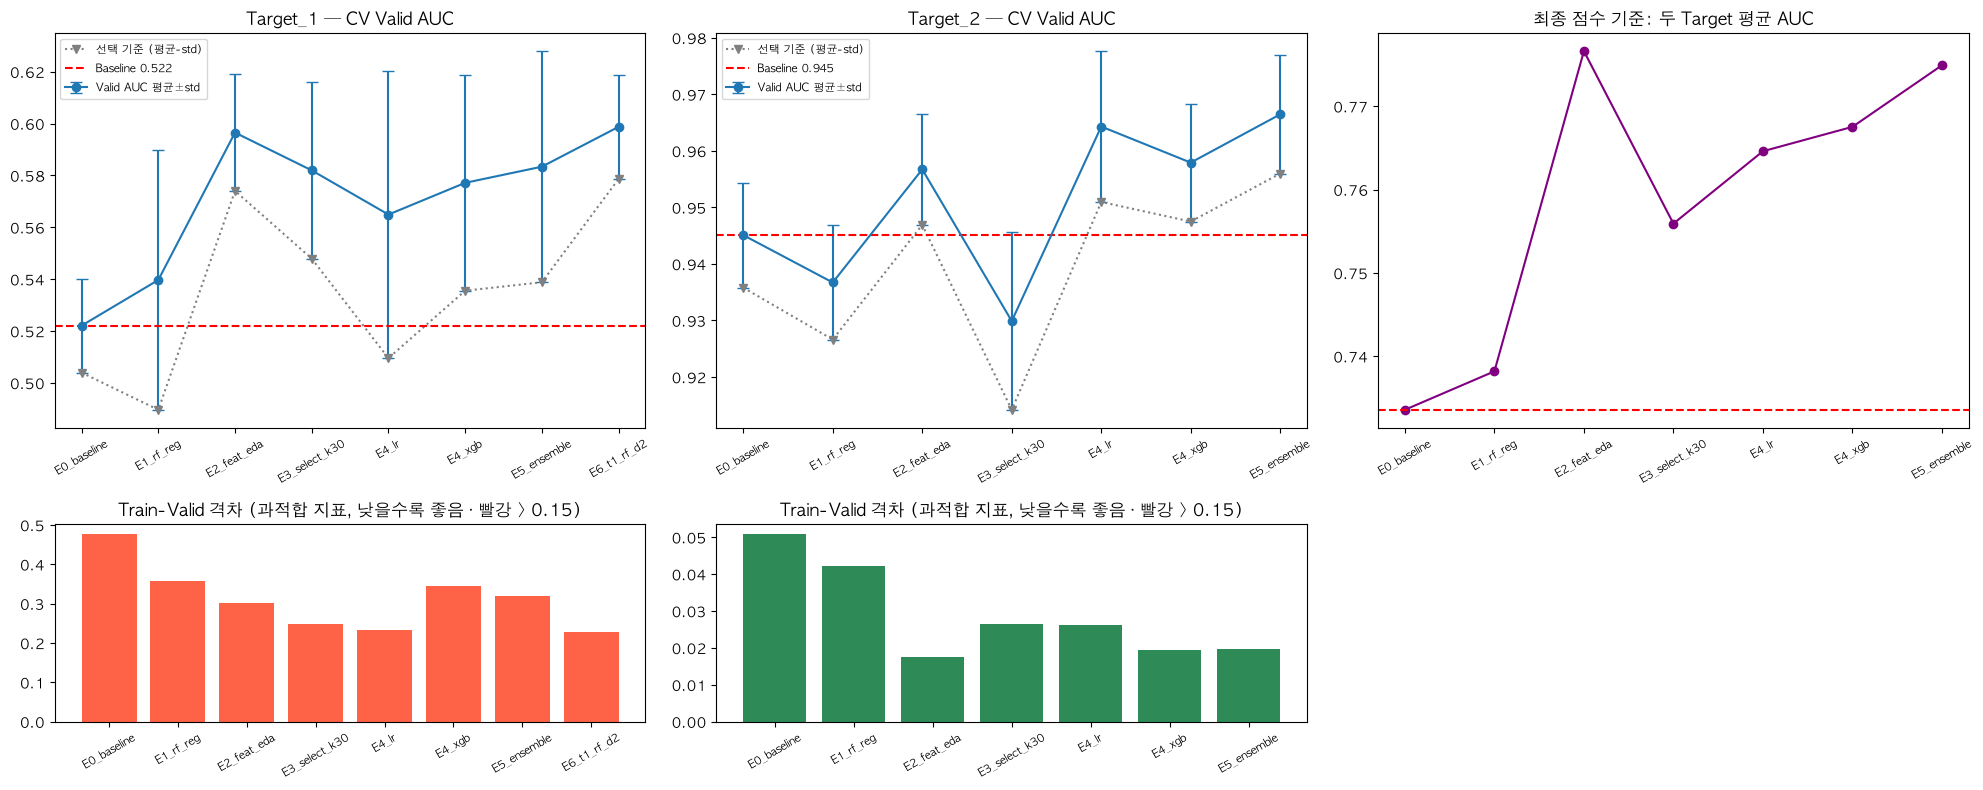

target,Target_1,Target_2,평균,Δ vs Baseline
name,,,,
E0_baseline,0.5221,0.9451,0.7336,0.0000
E1_rf_reg,0.5397,0.9367,0.7382,0.0046
E2_feat_eda,0.5965,0.9567,0.7766,0.0430
E3_select_k30,0.5819,0.9299,0.7559,0.0223
E4_lr,0.5649,0.9643,0.7646,0.0310
E4_xgb,0.5771,0.9579,0.7675,0.0339
E5_ensemble,0.5834,0.9665,0.7749,0.0413
E6_t1_rf_d2,0.5987,NaN,NaN,NaN


In [6]:
for t in TARGETS:
    run('E1_rf_reg', t, ['raw', 'chg1', 'wd_num'], pipe(rf_reg()), note='정규화 RF')
show_progress()

### E2. Target별 EDA 피처셋 (+ 정규화 RF)
가설: T2는 `d3ratio`로 요일 구조를 직접 모사, T1은 피처 수를 수십 개로 줄여 잡음 학습을 억제.

⏭  E2_feat_eda | Target_1: 캐시 사용  Valid 0.5965 ± 0.0225
⏭  E2_feat_eda | Target_2: 캐시 사용  Valid 0.9567 ± 0.0098


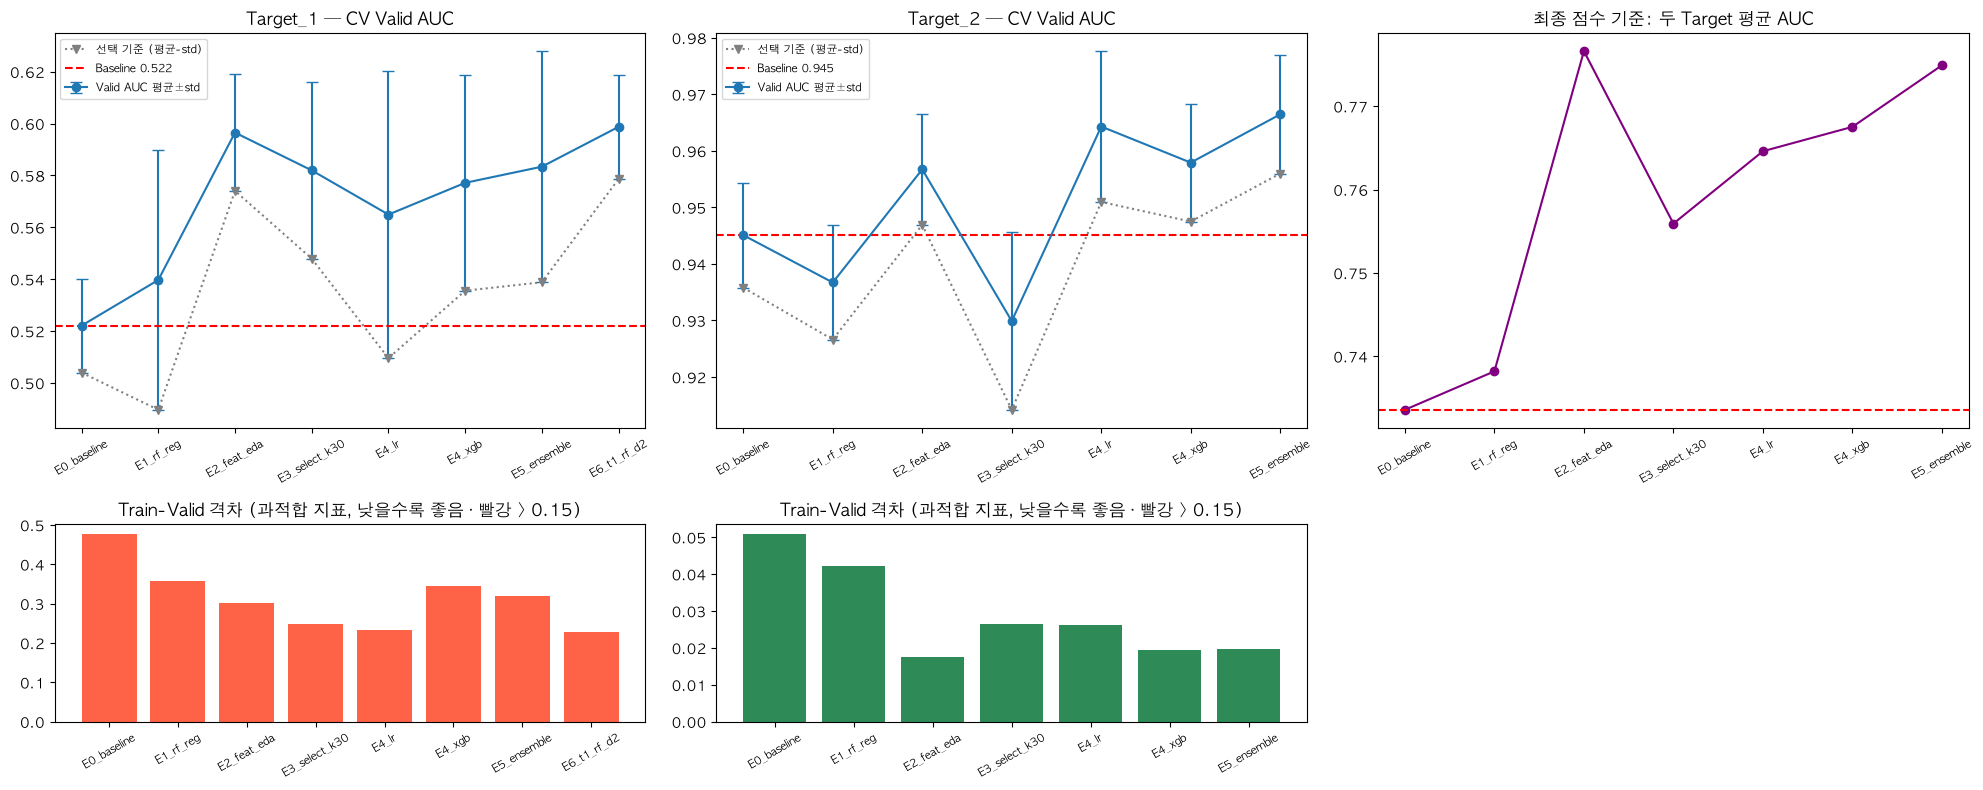

target,Target_1,Target_2,평균,Δ vs Baseline
name,,,,
E0_baseline,0.5221,0.9451,0.7336,0.0000
E1_rf_reg,0.5397,0.9367,0.7382,0.0046
E2_feat_eda,0.5965,0.9567,0.7766,0.0430
E3_select_k30,0.5819,0.9299,0.7559,0.0223
E4_lr,0.5649,0.9643,0.7646,0.0310
E4_xgb,0.5771,0.9579,0.7675,0.0339
E5_ensemble,0.5834,0.9665,0.7749,0.0413
E6_t1_rf_d2,0.5987,NaN,NaN,NaN


In [7]:
for t in TARGETS:
    run('E2_feat_eda', t, FEATS[t], pipe(rf_reg()), note='Target별 피처셋')
show_progress()

### E3. 후보 확장 + fold 내 Selection
가설: 후보를 넓히되(`chg1` 추가) **fold Train에서만** 상위 k개를 고르면, 사람이 EDA로 고른 것보다 나을 수 있다. 나빠지면 E2 유지.

⏭  E3_select_k30 | Target_1: 캐시 사용  Valid 0.5819 ± 0.0340
⏭  E3_select_k30 | Target_2: 캐시 사용  Valid 0.9299 ± 0.0157


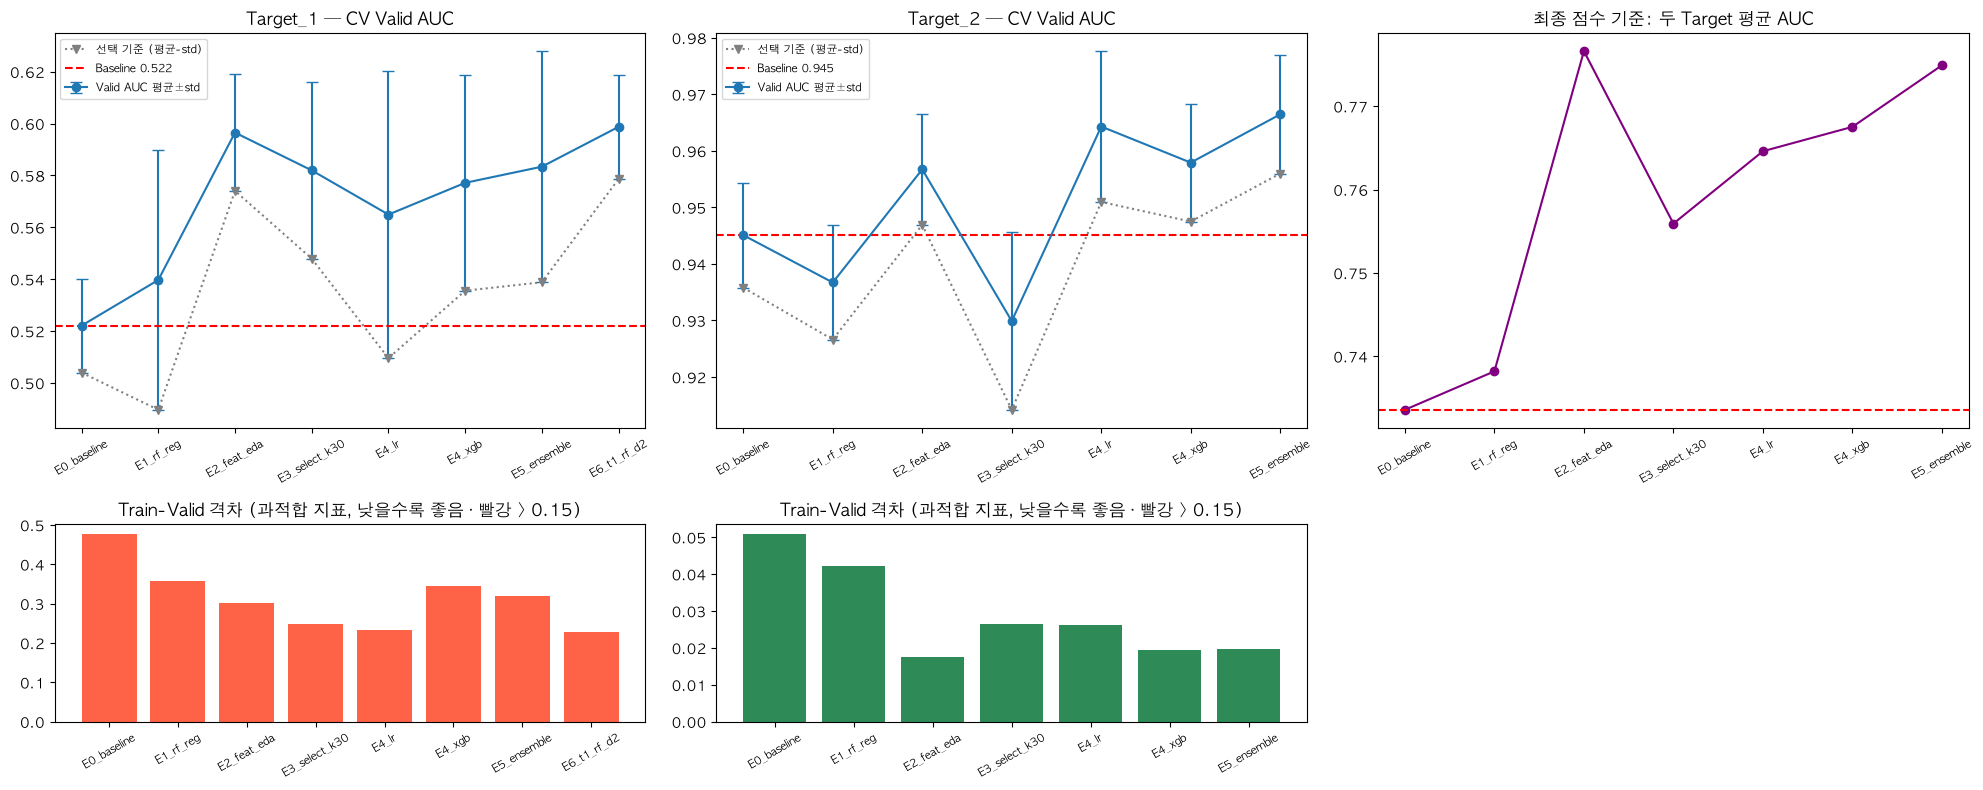

target,Target_1,Target_2,평균,Δ vs Baseline
name,,,,
E0_baseline,0.5221,0.9451,0.7336,0.0000
E1_rf_reg,0.5397,0.9367,0.7382,0.0046
E2_feat_eda,0.5965,0.9567,0.7766,0.0430
E3_select_k30,0.5819,0.9299,0.7559,0.0223
E4_lr,0.5649,0.9643,0.7646,0.0310
E4_xgb,0.5771,0.9579,0.7675,0.0339
E5_ensemble,0.5834,0.9665,0.7749,0.0413
E6_t1_rf_d2,0.5987,NaN,NaN,NaN


In [8]:
for t in TARGETS:
    run('E3_select_k30', t, FEATS[t] + ['chg1'], pipe(rf_reg(), k=30), note='fold 내 SelectKBest k=30')
show_progress()

### E4. 모델 비교 (같은 피처셋 E2)
- 로지스틱(L2, C=0.1): 가장 단순 → 잡음이 많은 T1에서 강할 수 있음
- XGBoost(얕은 깊이·작은 학습률·강한 L2)

✅ E4_lr | Target_1: Valid 0.5649 ± 0.0554 | Train 0.7970 | 0.1s
✅ E4_lr | Target_2: Valid 0.9643 ± 0.0133 | Train 0.9904 | 0.0s


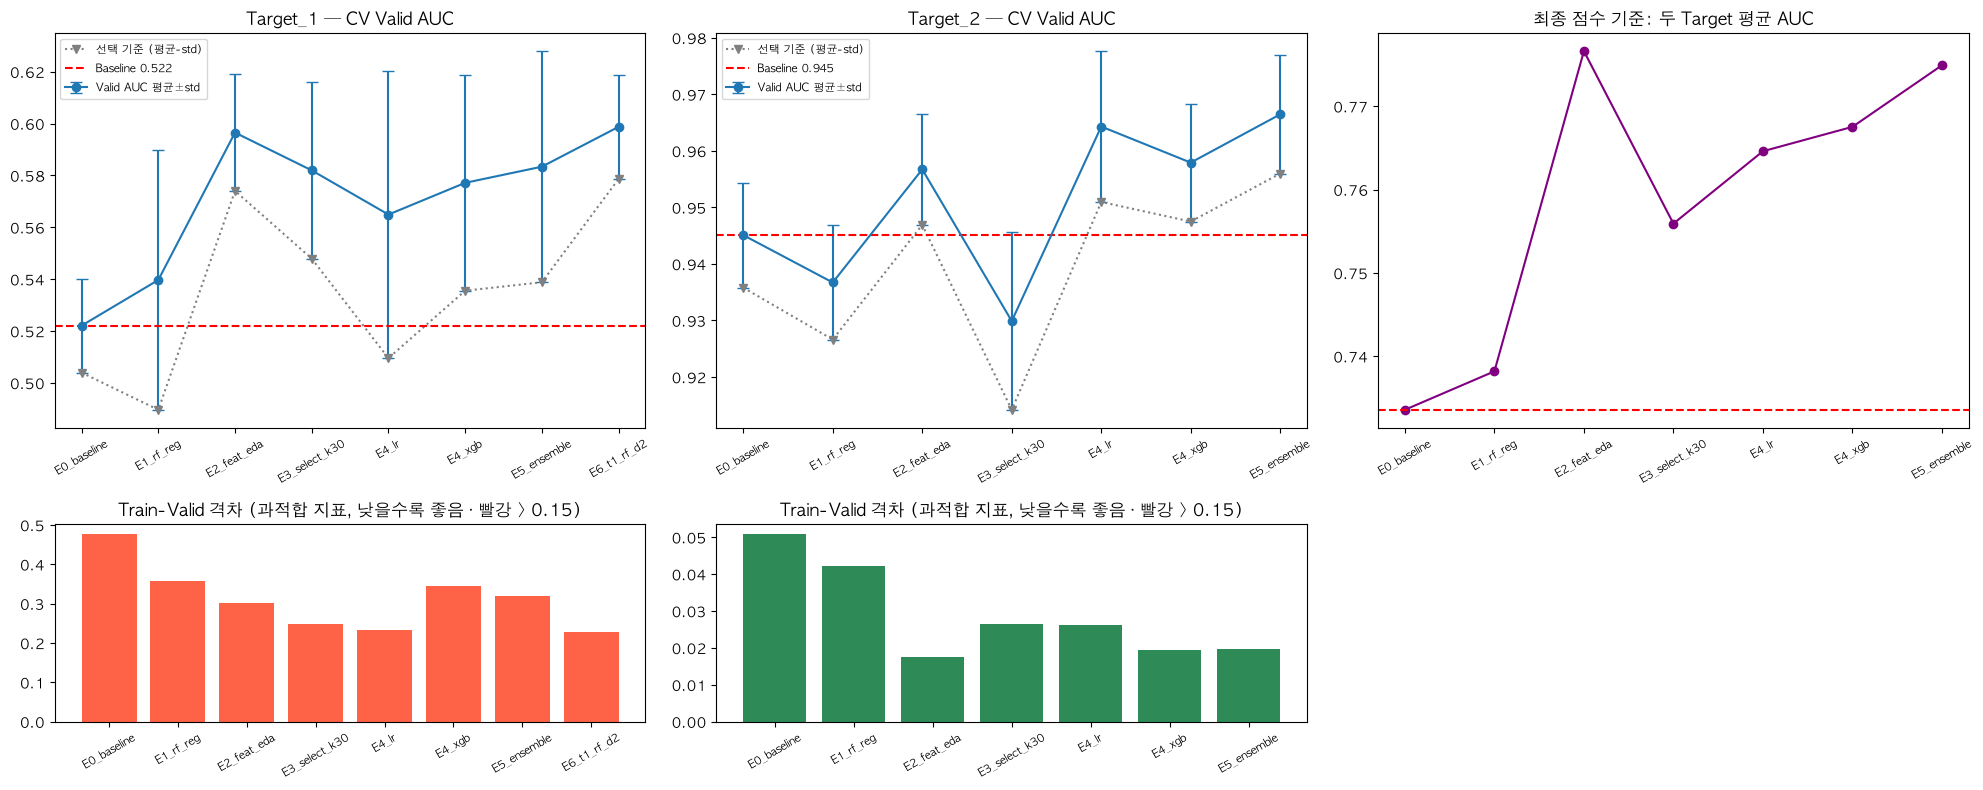

target,Target_1,Target_2,평균,Δ vs Baseline
name,,,,
E0_baseline,0.5221,0.9451,0.7336,0.0000
E1_rf_reg,0.5397,0.9367,0.7382,0.0046
E2_feat_eda,0.5965,0.9567,0.7766,0.0430
E3_select_k30,0.5819,0.9299,0.7559,0.0223
E4_lr,0.5649,0.9643,0.7646,0.0310
E4_xgb,0.5771,0.9579,0.7675,0.0339
E5_ensemble,0.5834,0.9665,0.7749,0.0413
E6_t1_rf_d2,0.5987,NaN,NaN,NaN


In [9]:
for t in TARGETS:
    run('E4_lr', t, FEATS[t], pipe(lr_reg(), scale=True), note='L2 로지스틱')
    if XGBClassifier is not None:
        run('E4_xgb', t, FEATS[t], pipe(xgb_reg()), note='정규화 XGB')
show_progress()

### E5. 소프트보팅 앙상블 (LR + RF + XGB)
가설: 서로 다른 오류를 내는 모델의 확률 평균 → **fold 간 표준편차 감소** (Private 안정성).

✅ E5_ensemble | Target_1: Valid 0.5788 ± 0.0525 | Train 0.8571 | 1.0s
✅ E5_ensemble | Target_2: Valid 0.9671 ± 0.0106 | Train 0.9865 | 1.0s


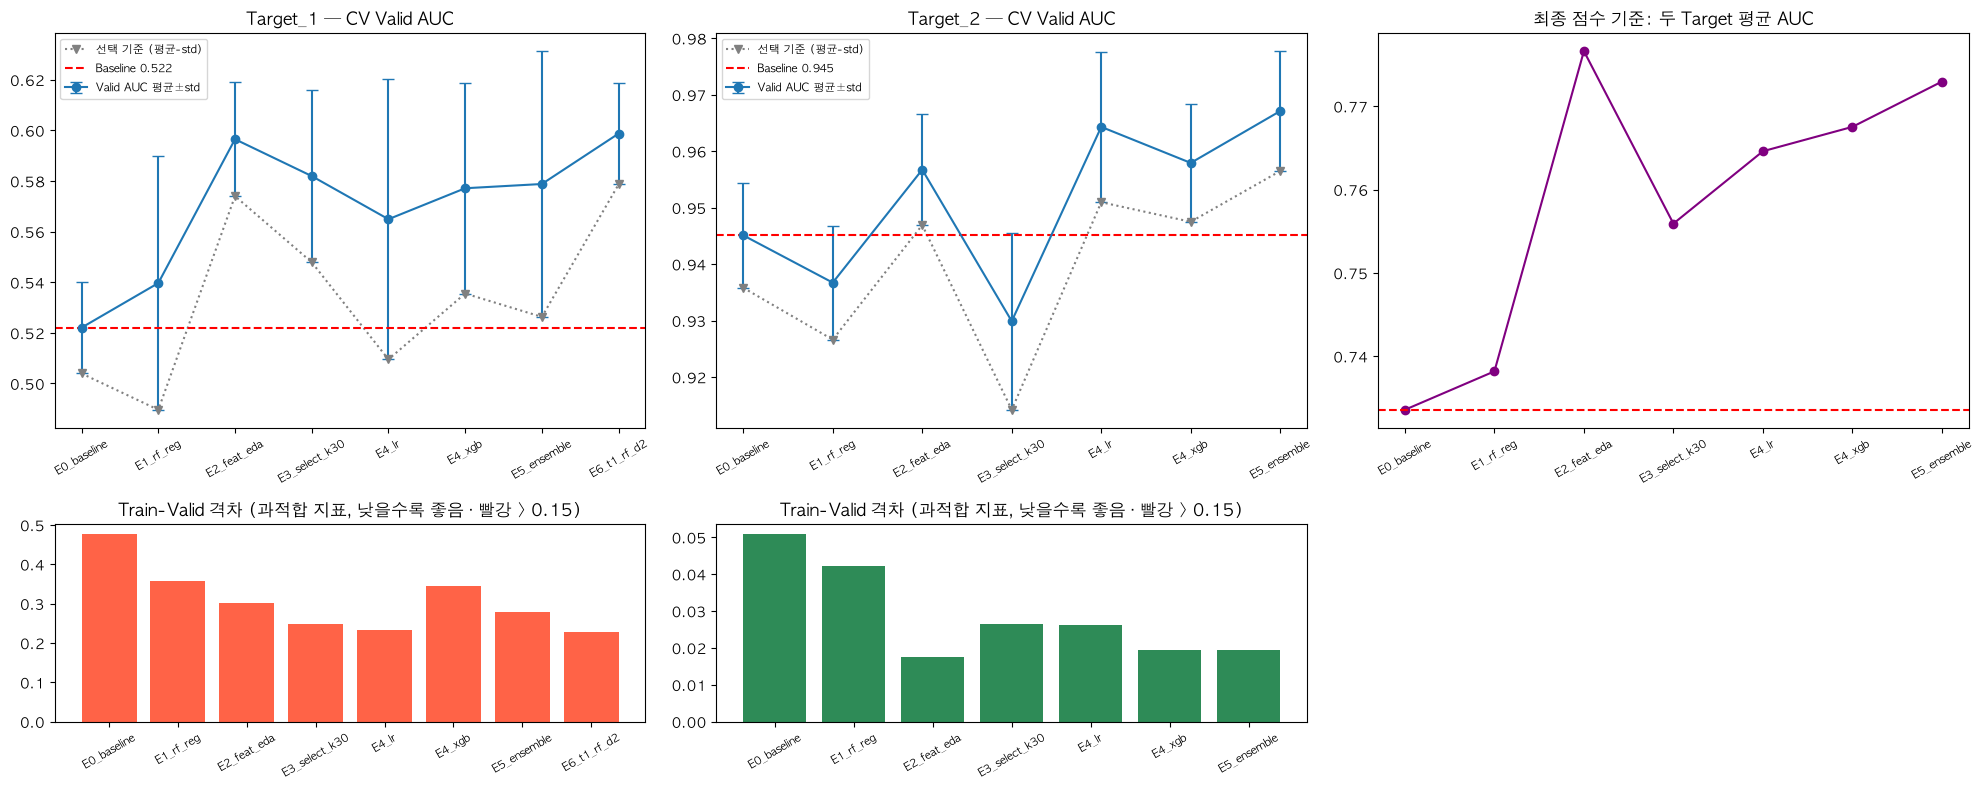

target,Target_1,Target_2,평균,Δ vs Baseline
name,,,,
E0_baseline,0.5221,0.9451,0.7336,0.0000
E1_rf_reg,0.5397,0.9367,0.7382,0.0046
E2_feat_eda,0.5965,0.9567,0.7766,0.0430
E3_select_k30,0.5819,0.9299,0.7559,0.0223
E4_lr,0.5649,0.9643,0.7646,0.0310
E4_xgb,0.5771,0.9579,0.7675,0.0339
E5_ensemble,0.5788,0.9671,0.7730,0.0394
E6_t1_rf_d2,0.5987,NaN,NaN,NaN


In [10]:
def ensemble():
    est = [('lr', pipe(lr_reg(), scale=True)), ('rf', pipe(rf_reg()))]
    if XGBClassifier is not None: est.append(('xgb', pipe(xgb_reg())))
    return VotingClassifier(est, voting='soft')

for t in TARGETS:
    run('E5_ensemble', t, FEATS[t], ensemble(), note='LR+RF+XGB soft voting')
show_progress()

### E6. T1 정규화 그리드 결과 반영 (백로그 2)
E2 피처셋에서 소규모 그리드(CV 기준)를 돌린 결과 (평균−std):
- RF `max_depth` 2·3·4·6 × `min_samples_leaf` 20·40·80 → **depth는 거의 무관, leaf 20이 최선**. depth 2·leaf 20: 0.579 (E2 0.574), Train−Valid 격차 0.30 → 0.23
- LR `C` 0.003~0.1 × SelectKBest `k` 10·20·전체 → 격차는 작지만(≈0.10) fold 편차가 커서 최고 0.536
- 금융 피처 축소(chg1만 / 미국지수 chg1만 / chg1+vol20) → 0.546~0.569로 모두 E2보다 낮음 → 피처는 E2 유지

→ 하이퍼파라미터는 T1의 병목이 아님. 개선폭(+0.005)은 잡음 수준이지만 **같은 성능에 더 단순한 모델**이라 채택한다.

⏭  E6_t1_rf_d2 | Target_1: 캐시 사용  Valid 0.5987 ± 0.0201


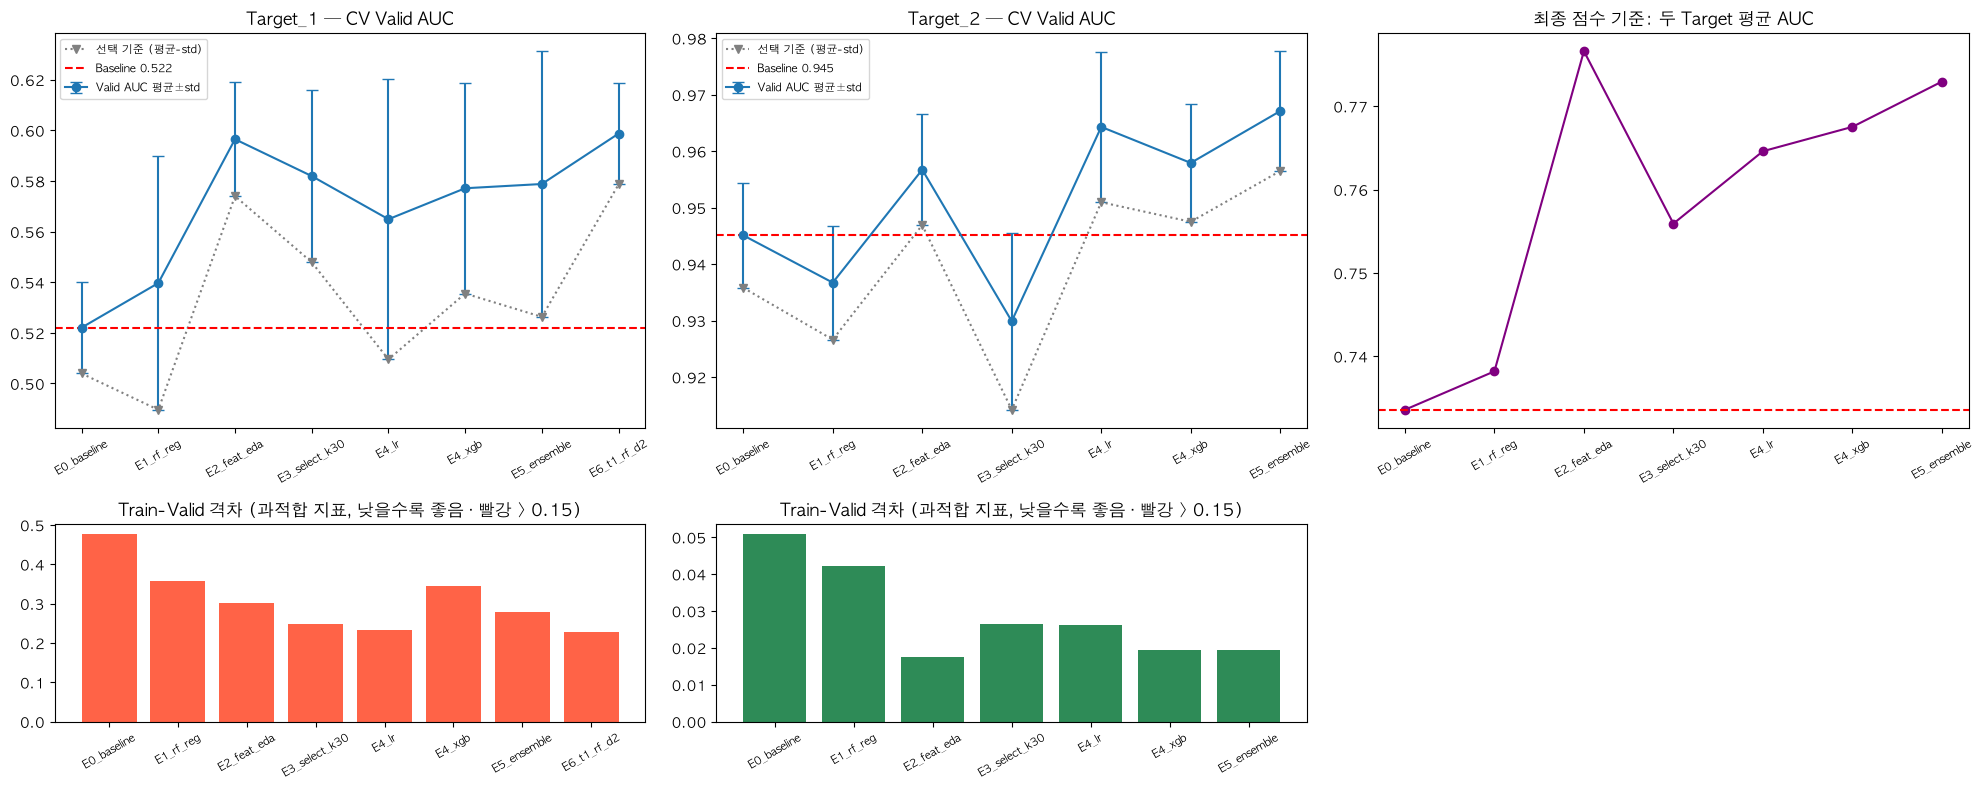

target,Target_1,Target_2,평균,Δ vs Baseline
name,,,,
E0_baseline,0.5221,0.9451,0.7336,0.0000
E1_rf_reg,0.5397,0.9367,0.7382,0.0046
E2_feat_eda,0.5965,0.9567,0.7766,0.0430
E3_select_k30,0.5819,0.9299,0.7559,0.0223
E4_lr,0.5649,0.9643,0.7646,0.0310
E4_xgb,0.5771,0.9579,0.7675,0.0339
E5_ensemble,0.5788,0.9671,0.7730,0.0394
E6_t1_rf_d2,0.5987,NaN,NaN,NaN


In [11]:
def rf_d2():   # E6: rf_reg에서 depth만 4 → 2
    return RandomForestClassifier(n_estimators=300, max_depth=2, min_samples_leaf=20, max_features='sqrt', random_state=SEED, n_jobs=-1)

run('E6_t1_rf_d2', 'Target_1', FEATS['Target_1'], pipe(rf_d2()), note='T1 그리드 최선 depth2 leaf20')
show_progress()

### 4-A. 블록 제거 실험 — 각 피처 블록이 정말 필요한가 (fold별 판정)
기준 모델(T1 = E6, T2 = E5)에서 블록 하나만 빼고 같은 CV를 돌린다. 평균만 보면 우연한 차이에 속기 쉬우므로 **fold별로 비교**한다.

**판정 규칙**: 블록을 뺐을 때
1. 5개 fold 중 **4개 이상에서 AUC가 하락**하고
2. 평균 하락폭이 **기준 모델 fold 표준편차의 절반 이상**일 때만 → **유지**

둘 중 하나라도 못 넘으면 → **제거 후보**(넣어도 빼도 차이가 잡음 수준).

- 실험 이름은 `A_`로 시작하고 `experiments.csv`에 기록된다. **진단용이라 §5 최종 선택에서는 제외**한다.

In [ ]:
ABLATION = {   # target: (기준 실험, 기준 블록, 모델 팩토리, 뺄 블록들)
    'Target_1': ('E6_t1_rf_d2', FEATS['Target_1'], lambda: pipe(rf_d2()), ['samewd_grp']),
    'Target_2': ('E5_ensemble', FEATS['Target_2'], ensemble, ['d3ratio', 'z20_kw']),
}

def judge(base, name, target):
    """fold별 판정: 블록을 빼서 4개 이상 fold 하락 + 평균 하락 ≥ 기준 std/2 → 유지"""
    log = load_log().set_index(['name', 'target'])
    b, a = (np.array(json.loads(log.loc[(n, target), 'folds'])) for n in (base, name))
    drop = b - a                                       # +면 블록을 빼서 성능이 떨어진 것 = 블록이 기여
    thr = log.loc[(base, target), 'valid_std'] / 2
    keep = (drop > 0).sum() >= 4 and drop.mean() >= thr
    return dict(target=target, 뺀블록=name.split('-', 1)[-1], 하락fold수=int((drop > 0).sum()),
                평균하락=drop.mean(), 기준std절반=thr, 판정='유지' if keep else '제거 후보', fold별하락=np.round(drop, 4).tolist())

verdicts = []
for t, (base, blocks, make, drops) in ABLATION.items():
    for blk in drops:
        name = f'A_{base.split("_")[0]}-{blk}'
        run(name, t, [b for b in blocks if b != blk], make(), note=f'{base}에서 {blk} 제거 (진단용)')
        verdicts.append(judge(base, name, t))
verdicts = pd.DataFrame(verdicts)

fig, ax = plt.subplots(1, len(verdicts), figsize=(6 * len(verdicts), 3.8))
for a, r in zip(np.atleast_1d(ax), verdicts.itertuples()):
    a.bar([f'fold{k + 1}' for k in range(5)], r.fold별하락, color=['seagreen' if d > 0 else 'tomato' for d in r.fold별하락])
    a.axhline(0, c='k', lw=.8); a.axhline(r.기준std절반, c='gray', ls='--', label=f'기준 std/2 = {r.기준std절반:.4f}')
    a.axhline(r.평균하락, c='navy', label=f'평균 하락 = {r.평균하락:+.4f}')
    a.set_title(f'{r.target}: {r.뺀블록} 제거 → {r.판정}\n(초록 = 빼면 하락 = 기여 {r.하락fold수}/5)'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
verdicts.round(4)

### E7. T1 금융 피처 중복 정리 (상관 0.8 이상은 대표 하나만)
`fi_chg`는 금융 18개 × (1·3·5일 변화율 + 20일 변동성) = 72개다. S&P500과 다우처럼 거의 같이 움직이는 변수가 섞여 있어 같은 정보를 여러 번 넣고 있다.

**방법**
- 상관은 **Train 행만, 전일 대비 변화율 기준**으로 계산한다. 원값끼리는 둘 다 추세가 있으면 관계가 없어도 상관이 높게 나오기 때문이다.
- 열 순서대로 훑으면서, 이미 남긴 변수와 |상관| ≥ 0.8이면 뺀다 → 각 묶음에서 **열 순서상 앞의 변수가 대표**가 된다.
- Target을 쓰지 않는 기준이라 Leakage가 없다.
- 예상 결과: 다우↔S&P500, 브렌트↔WTI, 휘발유↔경유 → 3개 제외, 15개 × 4 = 60개.
- 모델은 E6(RF depth 2)과 같게 두어 **피처 차이만** 비교한다.

In [ ]:
fi_chg1 = X0[cols('FI')].pct_change(1, fill_method=None).replace([np.inf, -np.inf], np.nan)[is_tr]   # Train 행만
fi_corr = fi_chg1.corr().abs()
fi_keep = []
for c in fi_corr:                                   # 열 순서대로: 이미 남긴 변수와 |상관| < 0.8 일 때만 남김
    if all(fi_corr.loc[c, k] < 0.8 for k in fi_keep): fi_keep.append(c)
fi_drop = {c: fi_corr.loc[c, fi_keep].idxmax() for c in fi_corr if c not in fi_keep}
print('제외 → 대표:', {k: f'{v} (상관 {fi_corr.loc[k, v]:.2f})' for k, v in fi_drop.items()})

BLOCKS['fi_chg_dedup'] = BLOCKS['fi_chg'][[c for c in BLOCKS['fi_chg'] if c.rsplit('_', 1)[0] in fi_keep]]
print('fi_chg', BLOCKS['fi_chg'].shape[1], '→ fi_chg_dedup', BLOCKS['fi_chg_dedup'].shape[1])

run('E7_t1_fi_dedup', 'Target_1', ['fi_chg_dedup', 'samewd_grp', 'wd_onehot'], pipe(rf_d2()), note='금융 상관≥0.8 대표만 + RF d2')
show_progress()
display(pd.DataFrame([judge('E7_t1_fi_dedup', 'E6_t1_rf_d2', 'Target_1')]).rename(columns={'뺀블록': '비교'})
        .assign(비교='E6(중복 포함) 대비 E7', 판정=lambda d: d.판정.map({'유지': 'E7이 확실히 나음', '제거 후보': '차이 잡음 수준'}))
        [['비교', '하락fold수', '평균하락', '기준std절반', '판정', 'fold별하락']]
        .rename(columns={'하락fold수': 'E7이 나은 fold수', '평균하락': 'E7 평균 개선', 'fold별하락': 'fold별 개선(E7−E6)'}).round(4))

### E8. T1 주말 보정 — 미국 지수 '마지막 거래일 변화율' 추가
**문제**: 요일 1·7(일·토)은 휴장일이라 금융 값이 전날 값 그대로다(국내 유가 제외 16개 변수 100%). 그래서 T1의 핵심 피처인 미국 지수 `chg1`이 **주말 행(전체의 2/7)에서 항상 0**이고, 주말에는 정보를 주지 못한다(주말 단일 AUC = 0.5).

**보정**: 변화율이 0인 날(휴장으로 값이 멈춘 날)은 **가장 최근에 실제로 움직인 거래일의 변화율**로 채운다.
- `chg1`에서 0을 결측으로 바꾼 뒤 앞의 값으로 채운다(`ffill`, 최대 3일). → 토·일에는 금요일의 등락이 들어간다.
- **과거 값만** 쓴다(앞으로 채우기 = 이전 날짜의 값 사용) → Leakage 없음. Test 행도 자기 이전 날짜만 참조한다.
- 미국 지수 3개(S&P500·다우·나스닥)에만 적용한다. 금융 18개 전체에 적용하면 피처만 늘고 성능이 떨어졌다(scratch 실험).
- 모델·나머지 피처는 E6과 같게 두어 **이 블록의 효과만** 비교한다.

In [ ]:
us_chg1 = X0[['FI_Sp500', 'FI_Dow', 'FI_Nasdaq']].pct_change(1, fill_method=None).replace([np.inf, -np.inf], np.nan)
BLOCKS['us_last'] = us_chg1.mask(us_chg1 == 0).ffill(limit=3).add_suffix('_last')   # 휴장일(0) → 직전 거래일 변화율 (과거만)

# 주말에 정보가 살아났는지: 요일별 단일 AUC (Train, 미국 지수 3개 평균)
wd_tr, y1 = full.loc[is_tr, 'Weekday'].values, Y['Target_1']
cmp_wd = pd.DataFrame({name: [roc_auc_score(y1[wd_tr == d], s[is_tr][wd_tr == d].fillna(0)) for d in range(1, 8)]
                       for name, s in {'chg1 (기존)': us_chg1.mean(axis=1), 'last (보정)': BLOCKS['us_last'].mean(axis=1)}.items()},
                      index=['일', '월', '화', '수', '목', '금', '토'])
display(cmp_wd.T.round(3))

run('E8_t1_us_last', 'Target_1', FEATS['Target_1'] + ['us_last'], pipe(rf_d2()), note='E6 + 미국 지수 주말 보정(us_last)')
show_progress()
display(pd.DataFrame([judge('E8_t1_us_last', 'E6_t1_rf_d2', 'Target_1')])
        .assign(비교='E6 대비 E8', 판정=lambda d: d.판정.map({'유지': 'E8이 확실히 나음', '제거 후보': '차이 잡음 수준'}))
        [['비교', '하락fold수', '평균하락', '기준std절반', '판정', 'fold별하락']]
        .rename(columns={'하락fold수': 'E8이 나은 fold수', '평균하락': 'E8 평균 개선', 'fold별하락': 'fold별 개선(E8−E6)'}).round(4))

### 4-B. 변수별 요일 영향 유형 — 파생변수를 요일에 맞게 다시 설계하기 위한 분류
변수마다 요일 영향의 **모양**이 다르므로, 같은 변환을 일괄 적용하지 않고 유형별로 맞는 변환을 쓴다. (Train만 사용)

| 측정값 | 계산 | 의미 |
| --- | --- | --- |
| 요일 설명력 | 28일 이동평균 대비 편차를 요일별로 평균 → 그 분산 ÷ 전체 분산 | 변동 중 요일 주기로 설명되는 비율 |
| 주말 정체 | 요일 1·7(일·토)에서 전날과 값이 같은 비율 | 휴장으로 값이 멈추는가 |

| 유형 | 기준 | 맞는 변환 |
| --- | --- | --- |
| **A 주말 정체** | 주말 정체 > 0.9 | 휴장일을 건너뛴 **거래일 기준** 변화율 / 직전 거래일 값 유지 (`us_last`, `fi_td`) |
| **B 요일 주기 강함** | 요일 설명력 > 0.2 | **같은 요일끼리 비교**(`sameWD`, `d3ratio`, `sh1_anom`) 또는 7일 평균(주기 상쇄) |
| C 요일 주기 약함 | 0.05 ~ 0.2 | B와 같거나 일반 변화율 |
| D 요일 무관 | < 0.05 | 일반 변화율·z-score |

In [ ]:
tr_ = train[RAW].loc[:, train[RAW].nunique() > 1]
detr = tr_ - tr_.rolling(28, min_periods=7).mean()                 # 추세 제거 후 요일 효과만
wd_type = pd.DataFrame({
    '군': [c.split('_')[0] for c in tr_],
    '요일설명력': detr.groupby(train.Weekday).mean().var() / detr.var(),
    '주말정체': (tr_.diff() == 0)[train.Weekday.isin([1, 7])].mean(),
}, index=tr_.columns)
wd_type['유형'] = np.select([wd_type.주말정체 > .9, wd_type.요일설명력 > .2, wd_type.요일설명력 > .05],
                          ['A 주말정체', 'B 요일주기 강함', 'C 요일주기 약함'], 'D 요일무관')
kr_hol = ((train[['FI_CD91', 'FI_Corp3yr', 'FI_FX_USDKRW']].diff() == 0).all(axis=1) & ~train.Weekday.isin([1, 7])).sum()
print(f'평일인데 국내 금리·환율이 멈춘 날(한국 공휴일 추정): {kr_hol}일')
display(wd_type.groupby(['군', '유형']).size().unstack(fill_value=0))
display(wd_type.sort_values('요일설명력', ascending=False).head(5).round(3))

### E9 · E10. 요일 유형에 맞춘 파생변수 재설계
| 실험 | Target | 추가/교체 블록 | 아이디어 (유형) |
| --- | --- | --- | --- |
| E9_t1_fi_td | T1 | `fi_chg`+`us_last` → **`fi_td`** | 금융(A) 전체를 **거래일 기준** 1·3·5일 변화율 + 변동성으로 (휴장일 = 직전 거래일 값) |
| E9_t1_holiday | T1 | E8 + **`holiday`** | 오늘이 평일 공휴일 / 휴장일인지 (국내 금리·환율 정체로 추정, 과거·당일 값만) |
| E10_t2_sh1_anom | T2 | E5 + **`sh1_anom`** | 쇼핑 L1(B) 11개 각각 **오늘 ÷ 지난 4주 같은 요일 평균** = 요일을 지운 '오늘의 이상치' (높으면 3일 뒤 평균회귀) |
| E10_t2_d3split_hol | T2 | E5 + **`d3_split`** + `holiday` | `d3ratio`를 '순수 요일 패턴'과 '오늘 이상치', 요일 무관 추세(7일/28일 평균)로 분해 |

모델은 기준(T1 = E8의 RF depth 2, T2 = E5 앙상블)과 같게 두어 **피처 효과만** 비교한다. 모든 블록은 과거·당일 값만 사용한다.

In [ ]:
def td_chg(s, k):
    """휴장일(값 정체)을 건너뛴 k거래일 전 대비 변화율. 휴장일엔 직전 거래일 값을 유지 (과거만 사용)"""
    obs = s.where(s.diff() != 0); obs.iloc[0] = s.iloc[0]
    return obs.dropna().pct_change(k).reindex(s.index).ffill(limit=5)

FI_STALE = wd_type.index[wd_type.유형 == 'A 주말정체']                  # 유형 A = 국내 유가 제외 금융 16개
fi_td = {}
for c in cols('FI'):
    d1 = td_chg(X0[c], 1) if c in FI_STALE else X0[c].pct_change(1, fill_method=None)
    for k in (1, 3, 5):
        fi_td[f'{c}_td{k}'] = td_chg(X0[c], k) if c in FI_STALE else X0[c].pct_change(k, fill_method=None)
    fi_td[f'{c}_tdvol'] = d1.rolling(20).std()
BLOCKS['fi_td'] = pd.DataFrame(fi_td)

kr_stuck = (X0[['FI_CD91', 'FI_Corp3yr', 'FI_FX_USDKRW']].diff() == 0).all(axis=1)
BLOCKS['holiday'] = pd.DataFrame({'kr_holiday_today': (kr_stuck & ~full.Weekday.isin([1, 7])).astype(int),
                                  'kr_closed_today': kr_stuck.astype(int)})

same_wd_mean = lambda D: sum(D.shift(7 * k) for k in range(1, 5)) / 4          # 지난 4주 같은 요일 평균
BLOCKS['sh1_anom'] = (sh1 / same_wd_mean(sh1)).add_suffix('_anom')
fh = sh1[['SH1_쇼핑1_식품', 'SH1_쇼핑1_생활건강']].mean(axis=1)
BLOCKS['d3_split'] = pd.DataFrame({
    'wd_pattern': (sum(fh.shift(4 + 7 * k) for k in range(4)) / 4) / same_wd_mean(fh),   # D+3 요일 vs 오늘 요일 (평소)
    'today_anom': fh / same_wd_mean(fh),                                                   # 오늘 vs 같은 요일 평소
    'trend7_28': fh.rolling(7).mean() / fh.rolling(28).mean()})                            # 7일 평균 = 요일 주기 상쇄

run('E9_t1_fi_td', 'Target_1', ['fi_td', 'samewd_grp', 'wd_onehot'], pipe(rf_d2()), note='금융 거래일 기준 변화율')
run('E9_t1_holiday', 'Target_1', FEATS['Target_1'] + ['us_last', 'holiday'], pipe(rf_d2()), note='E8 + 공휴일/휴장 플래그')
run('E10_t2_sh1_anom', 'Target_2', FEATS['Target_2'] + ['sh1_anom'], ensemble(), note='E5 + 쇼핑L1 같은 요일 대비 이상치')
run('E10_t2_d3split_hol', 'Target_2', FEATS['Target_2'] + ['d3_split', 'holiday'], ensemble(), note='E5 + d3 분해 + 공휴일')
show_progress()

cmp_new = [judge(new, base, t) | {'실험': new} for t, base, news in
           [('Target_1', 'E8_t1_us_last', ['E9_t1_fi_td', 'E9_t1_holiday']),
            ('Target_2', 'E5_ensemble', ['E10_t2_sh1_anom', 'E10_t2_d3split_hol'])] for new in news]
log_ = load_log().set_index(['name', 'target'])
display(pd.DataFrame(cmp_new).assign(
            평균=lambda d: [log_.loc[(r.실험, r.target), 'valid_mean'] for r in d.itertuples()],
            std=lambda d: [log_.loc[(r.실험, r.target), 'valid_std'] for r in d.itertuples()],
            판정=lambda d: d.판정.map({'유지': '기준보다 확실히 나음', '제거 후보': '차이 잡음 수준'}))
        .rename(columns={'하락fold수': '기준보다 나은 fold수', '평균하락': '평균 개선'})
        [['target', '실험', '평균', 'std', '기준보다 나은 fold수', '평균 개선', '판정']].round(4))

### E11. T1 단순 모델 — 미국장 신호만 쓰는 로지스틱 회귀 (+ E8과 혼합)
**가설**: T1의 진짜 신호는 "직전 거래일 미국장 등락" 하나다(EDA §5, 요일 통제 후에도 유지). 나머지 80여 개 피처는 잡음이라, RF가 잡음까지 학습하며 손해를 본다.

| 실험 | 내용 |
| --- | --- |
| E11_t1_lr_us | `us_last`(S&P500·다우·나스닥의 최근 거래일 변화율) **3개만** + 로지스틱 회귀(C=0.01, 강한 L2 정규화) |
| E11_t1_blend | E8(RF, 85개 피처) 확률 50% + 위 LR 확률 50% (소프트보팅). 서로 다른 오류를 평균해 **fold 간 편차 감소** |

scratch 사전 점검: LR의 C는 0.01~0.1에서 안정(C=1은 0.579로 하락). 변동성 대비 등락·미국×환율·누적 등락·달력 피처·금융 18개 LR은 모두 효과 없음.

In [ ]:
from sklearn.compose import ColumnTransformer

def lr_us():     # us_last 3개만 쓰는 강한 정규화 로지스틱
    return pipe(LogisticRegression(C=0.01, max_iter=3000), scale=True)

def t1_blend():  # E8 피처 전체 → RF, 그중 us_last 3개 → LR, 확률 50:50 평균
    e8_cols, us_cols = list(make_X(FEATS['Target_1'] + ['us_last']).columns), list(BLOCKS['us_last'].columns)
    pick = lambda cols: ColumnTransformer([('pick', 'passthrough', cols)])
    rf = make_pipeline(pick(e8_cols), SimpleImputer(strategy='median'), rf_d2())
    lr = make_pipeline(pick(us_cols), SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=0.01, max_iter=3000))
    return VotingClassifier([('rf', rf), ('lr', lr)], voting='soft')

run('E11_t1_lr_us', 'Target_1', ['us_last'], lr_us(), note='LR(C=0.01) 미국 지수 최근 거래일 변화율 3개만')
run('E11_t1_blend', 'Target_1', FEATS['Target_1'] + ['us_last'], t1_blend(), note='E8(RF) + LR(us_last) 50:50')
show_progress()
display(pd.DataFrame([judge(n, 'E8_t1_us_last', 'Target_1') | {'실험': n} for n in ['E11_t1_lr_us', 'E11_t1_blend']])
        .assign(판정=lambda d: d.판정.map({'유지': 'E8보다 확실히 나음', '제거 후보': '차이 잡음 수준'}))
        .rename(columns={'하락fold수': 'E8보다 나은 fold수', '평균하락': '평균 개선', 'fold별하락': 'fold별 개선'})
        [['실험', 'E8보다 나은 fold수', '평균 개선', '기준std절반', '판정', 'fold별 개선']].round(4))

### E12. T1 LR 입력을 '차이(diff)'로 교체 + 환율 추가 (T1 심화 EDA 결과)
**발견 1 — 변화율(%) 왜곡**: 금융 값은 0~1 Min-Max 정규화라 0 근처 값이 많다(나스닥 19일, 금 23일). 이런 값으로 `pct_change`를 계산하면 폭발한다(금 최대 3433%, 원/달러 1600%, 나스닥 417%).
정규화 값의 **차이(diff)는 실제 변화량에 비례**하므로 왜곡이 없다. 미국 지수 평균 단일 AUC: 변화율 0.605(왜도 5.2) → **차이 0.616(왜도 −0.7)**, 앞·뒤 절반 모두 개선.

**발견 2 — 숨은 환율 신호**: 차이로 보면 **원/달러(0.439)·엔/원(0.430) 상승 = 원화 약세 → 3일 뒤 KOSPI 하락**이 앞·뒤 절반 모두 같은 방향으로 나타난다(변화율에서는 극단값에 묻혔음).

| 블록 | 내용 (모두 주말·휴장일엔 직전 거래일 값, 과거만) |
| --- | --- |
| `us_diff` | S&P500·다우·나스닥 최근 거래일 **차이** 3개 |
| `fx_diff` | 원/달러·엔/원 최근 거래일 **차이** 2개 |

**E12_t1_blend** = E8(RF, 기존 피처) 50% + LR(C=0.01, `us_diff`+`fx_diff`) 50%. RF 쪽 피처까지 차이로 바꾸면 3·5일 변화·변동성 정보가 빠져 0.589로 하락 → **LR 쪽만 교체**.

In [ ]:
def last_move(D):   # 휴장일(변화 0) → 직전 거래일 값 유지, inf 제거 (과거만)
    D = D.replace([np.inf, -np.inf], np.nan)
    return D.mask(D == 0).ffill(limit=3)

BLOCKS['us_diff'] = last_move(X0[['FI_Sp500', 'FI_Dow', 'FI_Nasdaq']].diff()).add_suffix('_dlast')
BLOCKS['fx_diff'] = last_move(X0[['FI_FX_USDKRW', 'FI_FX_JPYKRW']].diff()).add_suffix('_dlast')

def t1_blend2(lr_blocks=('us_diff', 'fx_diff')):   # E11과 같은 구조, LR 입력만 교체
    rf_cols = list(make_X(FEATS['Target_1'] + ['us_last']).columns)
    lr_cols = list(make_X(list(lr_blocks)).columns)
    pick = lambda cols: ColumnTransformer([('pick', 'passthrough', cols)])
    rf = make_pipeline(pick(rf_cols), SimpleImputer(strategy='median'), rf_d2())
    lr = make_pipeline(pick(lr_cols), SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=0.01, max_iter=3000))
    return VotingClassifier([('rf', rf), ('lr', lr)], voting='soft')

run('E12_t1_blend', 'Target_1', FEATS['Target_1'] + ['us_last', 'us_diff', 'fx_diff'], t1_blend2(), note='E8(RF) + LR(미국 diff + 환율 diff) 50:50')
show_progress()
display(pd.DataFrame([judge('E12_t1_blend', base, 'Target_1') | {'비교': f'{base} 대비 E12'} for base in ['E8_t1_us_last', 'E11_t1_blend']])
        .assign(판정=lambda d: d.판정.map({'유지': 'E12가 확실히 나음', '제거 후보': '차이 잡음 수준'}))
        .rename(columns={'하락fold수': 'E12가 나은 fold수', '평균하락': '평균 개선', 'fold별하락': 'fold별 개선'})
        [['비교', 'E12가 나은 fold수', '평균 개선', '기준std절반', '판정', 'fold별 개선']].round(4))

### E13. T1 LR에 유가 변화량 + 금융 키워드 심리 추가
E12의 LR 쪽에 후보를 하나씩 더해 비교했다(금리·원자재·위안화·며칠 누적·비선형·변동성 상호작용·혼합 비율은 효과 없음).

| 블록 | 내용 (과거 값만) | 단일 AUC (전체 / 앞 절반 / 뒤 절반) |
| --- | --- | --- |
| `oil_diff` | 브렌트·WTI·두바이유 최근 거래일 **차이** | 0.52~0.53 / 0.50~0.51 / 0.54~0.56 (약함) |
| `kefin_swd` | 금융 키워드 6개(대출·부동산·아파트·보험·실손보험·변액보험)의 **같은 요일 4주 평균 대비** 검색량 중앙값 | 0.581 / 0.550 / 0.606 |

- 핵심은 **부동산(0.598)·아파트(0.599)** 검색 심리다. 앞·뒤 절반 모두 같은 방향으로, 부동산·자산 관심이 평소보다 높으면 3일 뒤 KOSPI 상승 경향이 있다(투자 심리 대리 변수). 미국장·환율과는 다른 독립 정보다.
- 키워드는 요일 주기가 강한 B 유형(§4-B)이라 **같은 요일끼리 비교**한다.
- scratch 확인: seed 1·7에서도 평균 +0.016, OOF +0.02 재현. std 증가는 최고 fold 상승 때문(최저 fold는 유지).
- ⚠️ 후보 약 15개 중 고른 것이라 CV가 다소 낙관적일 수 있다(실제 개선 +0.01 안팎 예상).

In [ ]:
BLOCKS['oil_diff'] = last_move(X0[['FI_Brent', 'FI_WTI', 'FI_Dubai']].diff()).add_suffix('_dlast')
KE_FIN = ['KE_대출', 'KE_부동산', 'KE_아파트', 'KE_보험', 'KE_실손보험', 'KE_변액보험']
ke_fin = X0[KE_FIN]
BLOCKS['kefin_swd'] = (ke_fin / same_wd_mean(ke_fin)).median(axis=1).rename('kefin_swd_med').to_frame()   # 같은 요일 4주 평균 대비

LR13 = ('us_diff', 'fx_diff', 'oil_diff', 'kefin_swd')
run('E13_t1_blend', 'Target_1', FEATS['Target_1'] + ['us_last'] + list(LR13), t1_blend2(LR13),
    note='E12 + LR(유가 diff + 금융 키워드 심리)')
show_progress()
display(pd.DataFrame([judge('E13_t1_blend', base, 'Target_1') | {'비교': f'{base} 대비 E13'} for base in ['E12_t1_blend', 'E11_t1_blend']])
        .assign(판정=lambda d: d.판정.map({'유지': 'E13이 확실히 나음', '제거 후보': '차이 잡음 수준'}))
        .rename(columns={'하락fold수': 'E13이 나은 fold수', '평균하락': '평균 개선', 'fold별하락': 'fold별 개선'})
        [['비교', 'E13이 나은 fold수', '평균 개선', '기준std절반', '판정', 'fold별 개선']].round(4))

## 5. 최종 모델 선택 → 전체 Train 재학습

선택 기준: **CV Valid 평균 − 표준편차** 최대 (높으면서 안정적인 실험). 진단용 블록 제거 실험(`A_`)은 후보에서 제외. Public 점수는 기준에 넣지 않는다.
특정 실험으로 고정하려면 `FINAL_OVERRIDE`에 지정한다. 최종 학습은 Train 전체(CV의 Train+Valid)로 한다 (자료 p.8).

> **✅ 최종 확정 (2026-10-13, E13으로 갱신)**: T1 = `E13_t1_blend` (E8 RF + LR[미국 지수·환율·유가 diff + 금융 키워드 심리] 50:50), T2 = `E10_t2_sh1_anom` (E5 앙상블 + 쇼핑L1 같은 요일 대비 이상치).
> 두 Target 평균은 아래 §5-2 출력 참고. 세 지표(평균·평균−std·fold별 판정) 기준으로 선택했고 Public 점수는 반영하지 않았다.


In [12]:
FINAL_OVERRIDE = {}           # 예: {'Target_1': 'E4_lr'}

log = load_log().assign(score=lambda d: d.valid_mean - d.valid_std)
FINAL = {t: FINAL_OVERRIDE.get(t) or log[(log.target == t) & log.name.isin([n for n, tt in REG if tt == t and not n.startswith('A_')])]
                                     .sort_values('score').name.iloc[-1] for t in TARGETS}
display(log[log.apply(lambda r: FINAL.get(r.target) == r['name'], axis=1)]
        [['target', 'name', 'blocks', 'n_feat', 'valid_mean', 'valid_std', 'score', 'train_mean']].round(4))

pred = {}
for t, name in FINAL.items():
    blocks, model = REG[(name, t)]
    Xall = make_X(blocks)
    m = clone(model).fit(Xall[is_tr], Y[t])
    pred[t] = m.predict_proba(Xall[~is_tr])[:, 1]

,target,name,blocks,n_feat,valid_mean,valid_std,score,train_mean
13,Target_2,E5_ensemble,wd_onehot+d3ratio+z20_kw,69,0.9671,0.0106,0.9565,0.9865
14,Target_1,E6_t1_rf_d2,fi_chg+samewd_grp+wd_onehot,82,0.5987,0.0201,0.5786,0.8256


## 5-1. 최종 모델 vs Baseline 성능 비교 (시각화)

§5에서 고른 Target별 최종 모델을 원본 Baseline(E0)과 나란히 비교한다. 모두 **CV 검증 구간**(학습에 쓰지 않은 미래 구간) 기준이다.

| 그림 | 질문 | 읽는 법 |
| --- | --- | --- |
| ① fold별 Valid AUC | 특정 시기에만 좋은 것 아닌가? | 5개 fold(왼쪽 = 과거, 오른쪽 = 최근) **모두에서 파랑이 회색보다 높으면** 시기와 무관하게 개선된 것. 점선 0.5 = 동전 던지기 |
| ② ROC 곡선 | 전체적으로 상승일과 하락일을 잘 가르나? | 곡선이 **왼쪽 위로 붙을수록** 좋다. 대각선 = 무작위. 곡선 아래 면적이 AUC |
| ③ Train vs Valid | 외워서 맞힌 것 아닌가? | Train과 Valid 막대 차이(**격차**)가 클수록 과적합. Baseline T1은 Train 1.000인데 Valid 0.52 = 거의 다 외운 상태 |

> ⚠️ ②의 AUC가 ① fold 평균보다 낮을 수 있다(특히 T1). ②는 5개 fold의 예측을 **이어 붙여 한 번에** 계산하므로, fold마다 확률 수준이 다르면 순서가 섞여 손해를 본다. **Private 평가(200일을 한 번에 AUC 계산)는 ② 방식과 비슷하다** → T1의 실제 기대치는 ①보다 ② 쪽에 가깝게 잡는 것이 안전하다.

findfont: Failed to find font weight bold for AppleGothic, now using 400.


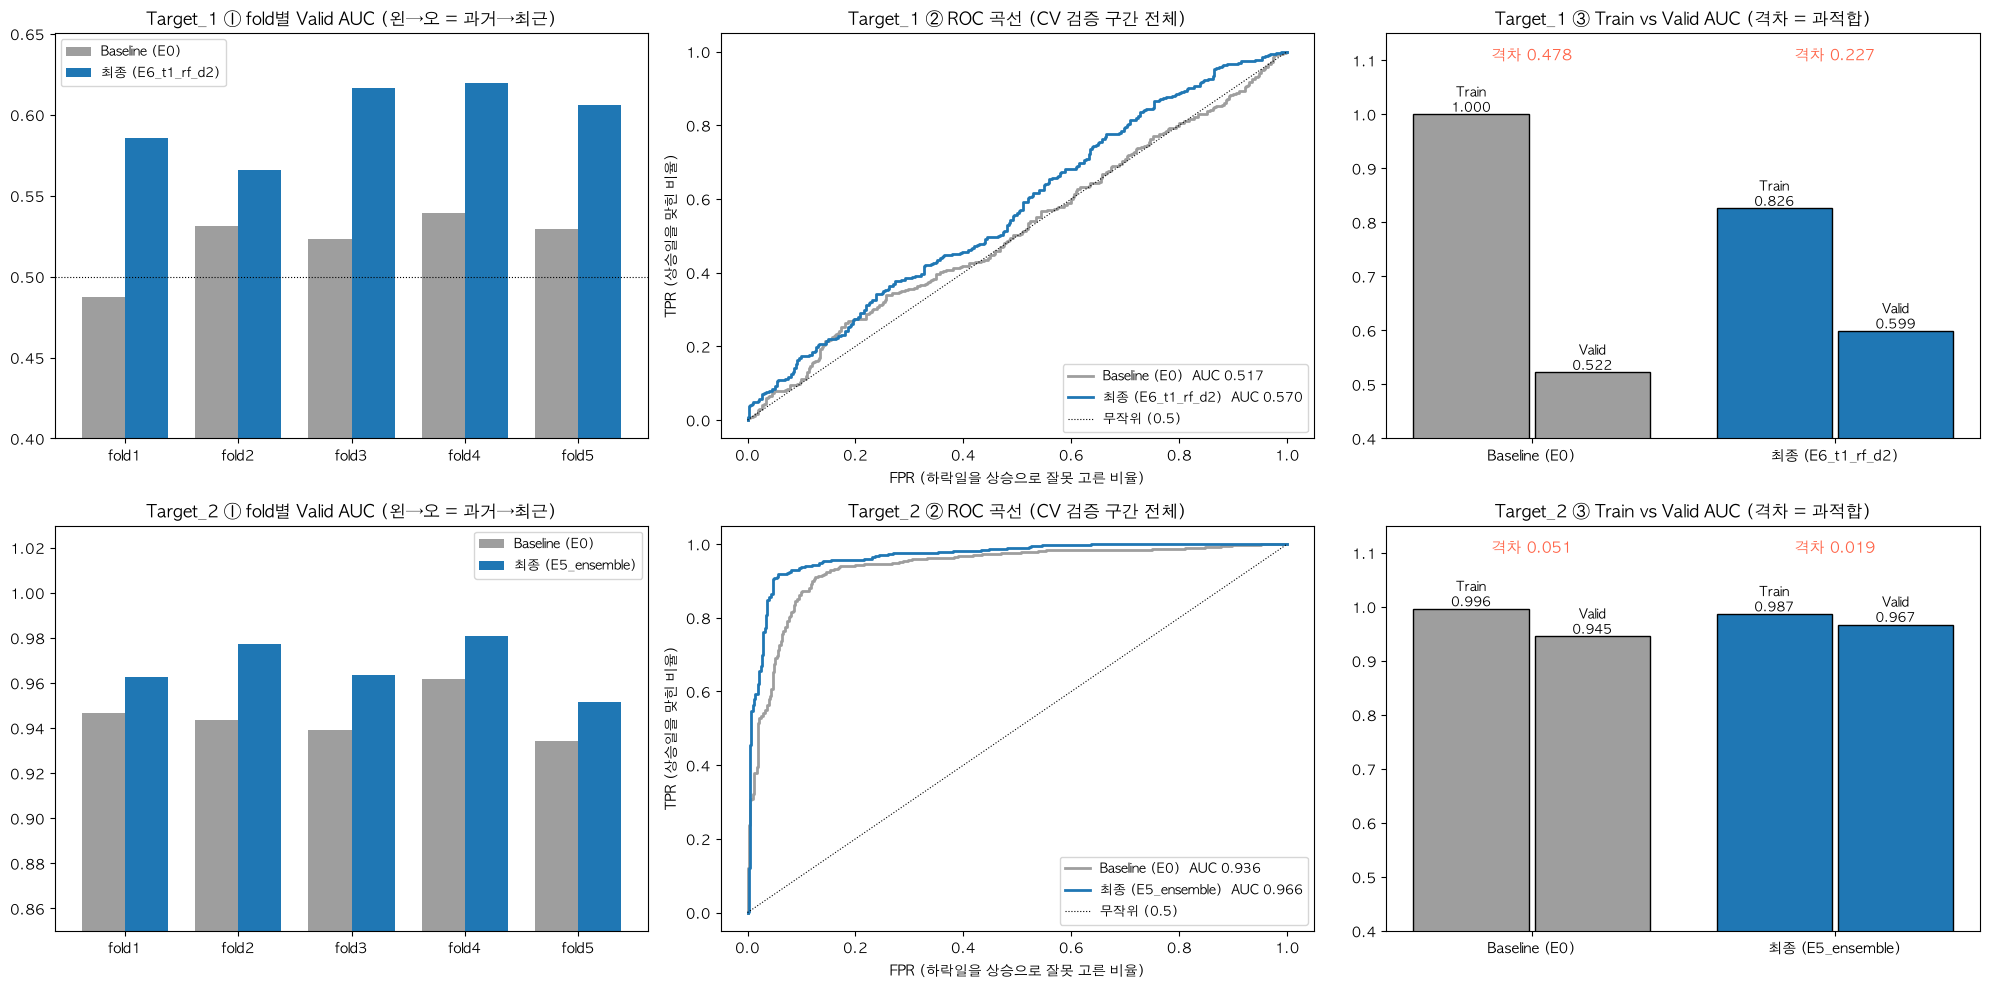

valid_mean  valid_std  평균_std  train_mean      격차
target   모델                                                                 
Target_1 Baseline (E0)         0.5221     0.0181  0.5040      0.9997  0.4776
         최종 (E6_t1_rf_d2)      0.5987     0.0201  0.5786      0.8256  0.2268
Target_2 Baseline (E0)         0.9451     0.0093  0.9358      0.9960  0.0509
         최종 (E5_ensemble)      0.9671     0.0106  0.9565      0.9865  0.0194

최종 점수 기준(두 Target 평균 CV AUC): Baseline 0.7336 → 최종 0.7829  (Δ +0.0493)


In [13]:
from sklearn.metrics import roc_curve

def oof_pred(model, Xd, y):
    """CV 각 fold의 Valid 예측을 이어 붙임 (= 매번 '처음 보는 미래'에 대한 예측)"""
    p = pd.Series(np.nan, index=Xd.index)
    for tr, va in TSCV.split(Xd):
        p.iloc[va] = clone(model).fit(Xd.iloc[tr], y.iloc[tr]).predict_proba(Xd.iloc[va])[:, 1]
    return p.dropna()

log = load_log().set_index(['name', 'target'])
fig, ax = plt.subplots(2, 3, figsize=(20, 10))
rows = []
for i, t in enumerate(TARGETS):
    names = {'Baseline (E0)': 'E0_baseline', f'최종 ({FINAL[t]})': FINAL[t]}
    colors = dict(zip(names, ['#9e9e9e', '#1f77b4']))
    # ① fold별 Valid AUC — 어느 시기에서나 이기는가
    w = 0.38
    for j, (lab, n) in enumerate(names.items()):
        f = json.loads(log.loc[(n, t), 'folds'])
        ax[i, 0].bar(np.arange(len(f)) + (j - .5) * w, f, w, label=lab, color=colors[lab])
    ax[i, 0].axhline(.5, c='k', lw=.8, ls=':'); ax[i, 0].set_xticks(range(5), [f'fold{k+1}' for k in range(5)])
    ax[i, 0].set_ylim(.4 if t == 'Target_1' else .85, None); ax[i, 0].legend(fontsize=9)
    ax[i, 0].set_title(f'{t} ① fold별 Valid AUC (왼→오 = 과거→최근)')
    # ② ROC — 전체 검증 구간을 이어 붙인 예측
    for lab, n in names.items():
        blocks, model = REG[(n, t)]
        Xd = make_X(blocks)[is_tr].reset_index(drop=True)
        p = oof_pred(model, Xd, Y[t]); y = Y[t].loc[p.index]
        fpr, tpr, _ = roc_curve(y, p)
        ax[i, 1].plot(fpr, tpr, c=colors[lab], lw=2, label=f'{lab}  AUC {roc_auc_score(y, p):.3f}')
    ax[i, 1].plot([0, 1], [0, 1], 'k:', lw=.8, label='무작위 (0.5)')
    ax[i, 1].set_xlabel('FPR (하락일을 상승으로 잘못 고른 비율)'); ax[i, 1].set_ylabel('TPR (상승일을 맞힌 비율)')
    ax[i, 1].set_title(f'{t} ② ROC 곡선 (CV 검증 구간 전체)'); ax[i, 1].legend(fontsize=9, loc='lower right')
    # ③ Train vs Valid — 과적합 격차
    for j, (lab, n) in enumerate(names.items()):
        r = log.loc[(n, t)]
        ax[i, 2].bar([j - .2, j + .2], [r.train_mean, r.valid_mean], .38, color=[colors[lab]] * 2, edgecolor='k')
        ax[i, 2].text(j - .2, r.train_mean + .005, f'Train\n{r.train_mean:.3f}', ha='center', fontsize=9)
        ax[i, 2].text(j + .2, r.valid_mean + .005, f'Valid\n{r.valid_mean:.3f}', ha='center', fontsize=9)
        ax[i, 2].text(j, 1.1, f'격차 {r.train_mean - r.valid_mean:.3f}', ha='center', fontsize=11, color='tomato', weight='bold')
        rows.append(dict(target=t, 모델=lab, valid_mean=r.valid_mean, valid_std=r.valid_std,
                         평균_std=r.valid_mean - r.valid_std, train_mean=r.train_mean, 격차=r.train_mean - r.valid_mean))
    ax[i, 2].set_xticks([0, 1], list(names)); ax[i, 2].set_ylim(.4, 1.15)
    ax[i, 2].set_title(f'{t} ③ Train vs Valid AUC (격차 = 과적합)')
plt.tight_layout(); plt.show()

cmp = pd.DataFrame(rows).set_index(['target', '모델'])
display(cmp.round(4))
base = cmp.xs('Baseline (E0)', level=1).valid_mean.mean()
final = np.mean([cmp.loc[(t, f'최종 ({FINAL[t]})'), 'valid_mean'] for t in TARGETS])
print(f'최종 점수 기준(두 Target 평균 CV AUC): Baseline {base:.4f} → 최종 {final:.4f}  (Δ {final - base:+.4f})')

## 5-2. 전체 실험 최종 비교 — `experiments.csv` 기준 (제출 모델 결정용)

진단용 블록 제거 실험(`A_`)을 뺀 **모든 제출 후보**를 Target별로 비교한다. 그림은 `최종_실험비교.png`로도 저장되어 보고서에 바로 쓸 수 있다.

| 그림 | 보는 것 | 판단 |
| --- | --- | --- |
| ① 평균±std 막대 | 막대 = fold 평균 AUC, 검은 세로선 = **평균−std(선택 기준)**, 주황 ◆ = **OOF AUC** | 세 표시가 모두 위쪽인 모델이 좋다. 위에서부터 선택 기준 순으로 정렬 |
| ② fold별 히트맵 | 5개 시기 각각의 AUC (초록 = 높음) | **한 시기에만 강한 모델보다 모든 열이 고르게 초록인 모델**이 Private(처음 보는 200일)에서 안전 |
| ③ Train−Valid 격차 | 과적합 정도 | 짧을수록 좋다. Baseline(E0) 대비 얼마나 줄었는지 확인 |

**OOF AUC란?** CV 각 fold의 검증 예측을 이어 붙여 **한 번에** 계산한 AUC다. Private은 200일을 한 번에 평가하므로 fold 평균보다 이 값이 실제 점수에 더 가깝다(보통 fold 평균보다 조금 낮다).

In [ ]:
# 진단용(A_)·Baseline 재현 계열을 제외한 '제출 후보'만 비교
log = load_log()
cand = log[~log.name.str.startswith('A_')].copy()
cand['평균-std'] = cand.valid_mean - cand.valid_std
cand['격차'] = cand.train_mean - cand.valid_mean
cand['fold'] = cand.folds.apply(json.loads)

# 이어붙인 OOF AUC: CV 검증 구간 예측을 한 번에 평가 (Private 200일 일괄 평가와 가장 비슷한 지표)
def oof_auc(name, t):
    blocks, model = REG[(name, t)]
    Xd = make_X(blocks)[is_tr].reset_index(drop=True)
    p = oof_pred(model, Xd, Y[t])
    return roc_auc_score(Y[t].loc[p.index], p)
cand['OOF AUC'] = [oof_auc(r.name, r.target) for r in cand.itertuples()]

fig, ax = plt.subplots(2, 3, figsize=(22, 11), gridspec_kw={'width_ratios': [3, 3, 2]})
for i, t in enumerate(TARGETS):
    d = cand[cand.target == t].sort_values('평균-std').reset_index(drop=True)
    best = d.name.iloc[-1]
    c = ['#1f77b4' if n == best else ('#d62728' if n == 'E0_baseline' else '#9e9e9e') for n in d.name]
    # ① 평균±std 와 평균-std (선택 기준)
    y = np.arange(len(d))
    ax[i, 0].barh(y, d.valid_mean, xerr=d.valid_std, color=c, alpha=.85, capsize=3)
    ax[i, 0].scatter(d['평균-std'], y, marker='|', s=300, c='k', zorder=3, label='평균-std (선택 기준)')
    ax[i, 0].scatter(d['OOF AUC'], y, marker='D', s=40, c='orange', zorder=3, label='OOF AUC (Private 유사)')
    ax[i, 0].set_yticks(y, d.name); ax[i, 0].set_xlim(.45 if t == 'Target_1' else .88, None)
    ax[i, 0].set_title(f'{t} ① CV Valid AUC 평균±std (파랑 = 선택, 빨강 = Baseline)'); ax[i, 0].legend(fontsize=8, loc='lower right')
    # ② fold별 AUC 히트맵: 어느 시기에서나 강한가
    F = np.vstack(d.fold.values)
    im = ax[i, 1].imshow(F, cmap='RdYlGn', aspect='auto', origin='lower', vmin=F.min(), vmax=F.max())
    for (r, k), v in np.ndenumerate(F): ax[i, 1].text(k, r, f'{v:.3f}', ha='center', va='center', fontsize=8)
    ax[i, 1].set_yticks(y, d.name); ax[i, 1].set_xticks(range(5), [f'fold{k + 1}' for k in range(5)])
    ax[i, 1].set_title(f'{t} ② fold별 Valid AUC (왼→오 = 과거→최근)')
    # ③ 과적합 격차
    ax[i, 2].barh(y, d['격차'], color=['tomato' if g > .15 else 'seagreen' for g in d['격차']])
    ax[i, 2].set_yticks(y, d.name); ax[i, 2].set_title(f'{t} ③ Train-Valid 격차 (빨강 > 0.15)')
plt.tight_layout(); plt.savefig('최종_실험비교.png', dpi=120, bbox_inches='tight'); plt.show()

table = (cand.sort_values(['target', '평균-std'], ascending=[True, False])
             [['target', 'name', 'n_feat', 'valid_mean', 'valid_std', '평균-std', 'OOF AUC', 'train_mean', '격차', 'note']])
display(table.round(4))
top = table.groupby('target').head(1).set_index('target')
print('선택 기준(평균−std) 1위 →', top.name.to_dict(),
      f'| 두 Target 평균 CV AUC {top.valid_mean.mean():.4f}, OOF {top["OOF AUC"].mean():.4f}')

## 6. 제출 파일 생성 + 형식 검증

⚠️ **MODE · 파일명 · 제출 주소**가 서로 맞는지 마지막으로 확인 (Private은 1회만 제출 가능).

In [14]:
sample = pd.read_csv(CFG['sample'], encoding='cp949')
sub = pd.DataFrame({'Time_step': full.loc[~is_tr, 'Time_step'].values,
                    'pred_1': pred['Target_1'], 'pred_2': pred['Target_2']})
sub = sample[['Time_step']].merge(sub, on='Time_step', how='left')[sample.columns]

assert list(sub.columns) == list(sample.columns), '컬럼명이 양식과 다름'
assert len(sub) == len(sample) and sub.notna().all().all(), '행 수 불일치 또는 결측 예측'
assert sub[['pred_1', 'pred_2']].apply(lambda s: s.between(0, 1).all()).all(), '확률 범위(0~1) 벗어남'
assert MODE in CFG['out'] and CFG['test'].startswith(f'test_{MODE}'), 'MODE와 파일 설정 불일치'

assert OVERWRITE or not os.path.exists(CFG['out']), f'{CFG["out"]} 이미 존재 → 회차(PUBLIC_ROUND)를 올리거나 OVERWRITE=True'
sub.to_csv(CFG['out'], index=False)
print(f'저장: {CFG["out"]}  ({len(sub)}행)  ← MODE={MODE}, 입력={CFG["test"]}')
print(f'제출 주소: {CFG["form"]}')

저장: public_4반_최승우_2.csv  (100행)  ← MODE=public, 입력=test_public.csv
제출 주소: https://forms.gle/S8X2XRqHtAGuvwgq5


## 7. 개선 백로그 (진행하면서 위에서부터 시도 → §4 아래에 E6~ 로 추가)

| 우선 | 아이디어 | 기대 효과 / 확인할 그래프 |
| --- | --- | --- |
| 1 | `d3ratio` 확장: 식품·생활건강 관련 SH2 세부 품목 추가, 평균 주수 2·4·8 비교 | T2 Valid 평균 ↑ |
| ~~2~~ | ~~T1 로지스틱 `C`, Selection `k`, RF depth·leaf 그리드~~ → **E6 완료** (RF depth2·leaf20 채택, 개선 미미) | T1 평균−std ↑ |
| 3 | seed 여러 개 평균 (RF/XGB) | 표준편차 ↓ |
| ~~4~~ | ~~T1 `samewd_grp` 제거 실험~~ → 완료: 제거 시 0.597→0.584, **유지** | 과적합 의심 피처 정리 |
| 5 | 날씨 블록 추가/제외 비교 (EDA상 신호 약함) | 변화 없으면 제외 유지 |
| 6 | Public 점수는 `experiments.csv`의 note에만 기록 — 선택 기준에 넣지 않기 | Public 과적합 방지 |
| ~~7~~ | **E8 완료** · T1 주말 보정: 주말(요일 1·7) 금융 변화율 = 0 → '마지막 거래일 변화율'(미국 지수 3개) 추가 (scratch에서 평균−std 0.579→0.585) | E8 후보 |
